# Evaluating coding agents through execution traces

**Success, failure, and the limits of observational benchmarking**

What can execution traces tell us about coding-agent performance, and how do evaluation design choices affect the conclusions? This study contributes a structural audit, linked analysis tables, a characterization of behaviour and outcomes, and an assessment of candidate outcome signals—including weak and null results—in a 370-attempt snapshot. Its contribution is an evidence-led evaluation case study, rather than a new benchmark or a causal ranking of models.

The prompts describe GitHub issue resolution with four tools (`read`, `bash`, `edit`, `write`). The records contain seven anonymized model labels, 15 jobs, and 253 task IDs. We use the recorded `OK` label as success; the grader implementation and underlying model identities are unavailable. References to the `pi` harness in the records do not establish its version or implementation. IL and TL meanings remain interpretations of observed patterns.

The narrative proceeds through **data and evaluation setting** (2–6), **behaviour and outcomes** (7–13), **candidate signals and null results** (14–17), and **reliability, cases, and evaluation design** (18–23). Every code result is rebuilt from the explicit Arrow snapshot; saved tables are never analysis inputs.

### Research context

[SWE-bench (Jimenez et al., ICLR 2024)](https://arxiv.org/abs/2310.06770) established real GitHub issue resolution as an executable evaluation setting. It motivates looking beyond isolated code completion, but does **not** establish that this snapshot uses SWE-bench tasks or its grader. [HELM (Liang et al., TMLR 2023)](https://arxiv.org/abs/2211.09110) motivates transparent, multi-metric evaluation under standardized conditions. Here we examine what can be learned when task coverage and run conditions are incomplete and unequal. These are contextual references, not claims that this study reproduces either benchmark.

## 2. Environment and reproducibility

Run `python scripts/run_analysis.py --dataset /path/to/agent-traces-train.arrow --output /path/to/fresh-results` from any directory, using an absolute script path if needed. The runner sets the project root, verifies the snapshot checksum, and executes a fresh kernel. It writes an executed notebook, HTML, figures, tables, and a checksummed output manifest. See the README for environment setup.

The workflow is offline after installation and data acquisition. Randomized estimators and graph layout use seed 20260721. GroupKFold is deterministic and unshuffled. Printed versions and run metadata record the environment; pinned direct dependencies are in `requirements.txt`.

In [1]:
import sys, os, json, re, warnings, platform, statistics
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
get_ipython().run_line_magic("matplotlib", "inline")

warnings.filterwarnings("ignore", category=FutureWarning)
# Optional widget progress bars are unnecessary for this static research notebook.
warnings.filterwarnings("ignore", message="IProgress not found.*")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

RANDOM_SEED = 20260721
np.random.seed(RANDOM_SEED)

PROJECT_ROOT = Path(os.environ.get("AGENT_TRACES_PROJECT_ROOT", ".")).resolve()
if not (PROJECT_ROOT / "agent_traces_lib.py").is_file():
    raise RuntimeError("Set AGENT_TRACES_PROJECT_ROOT to the repository root")
sys.path.insert(0, str(PROJECT_ROOT))
import agent_traces_lib as atl
DATASET_PATH = Path(os.environ["AGENT_TRACES_DATASET"]).expanduser().resolve()
OUT = Path(os.environ["AGENT_TRACES_OUTPUT"]).expanduser().resolve()
for sub in ["data_audit", "derived_tables", "figures", "case_studies", "final_summary"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)

atl.set_plot_style()

print("Python:", platform.python_version())
for mod_name in ["numpy", "pandas", "matplotlib", "sklearn", "scipy", "datasets", "networkx"]:
    try:
        mod = __import__(mod_name)
        print(f"{mod_name:12s} {getattr(mod, '__version__', '?')}")
    except ImportError as e:
        print(f"{mod_name:12s} NOT AVAILABLE ({e})")
print("\nRandom seed fixed at:", RANDOM_SEED)

Python: 3.11.15
numpy        2.4.6
pandas       3.0.3
matplotlib   3.10.9


sklearn      1.8.0
scipy        1.17.1
datasets     5.0.0
networkx     3.6.1

Random seed fixed at: 20260721


## 3. Dataset provenance and loading

We read an explicit local Arrow file using `Dataset.from_file`; there is no implicit cache lookup or network fallback. `data_snapshot.json` identifies the 370-row train snapshot by SHA-256. The Hub API independently confirmed revision `1be8b9a763288ba2a4efbf8c354bc66cffa50368`; this is not inferred from the cache directory name. See `docs/DATA.md` for acquisition, provenance, and unresolved redistribution rights.

The local metadata has empty description, citation, homepage, and license fields. We therefore avoid inventing dataset semantics or attribution beyond the uploader and source. Transformations create separate tables and do not modify the raw records.

In [2]:
ds = atl.load_raw_dataset(DATASET_PATH)
print(ds)
print("Columns:", ds.column_names)
print("Rows:", len(ds))

Dataset({
    features: ['model', 'job', 'trial', 'task_id', 'status', 'reward', 'n_proxy_requests', 'proxy_requests', 'system_prompt', 'tools', 'conversation'],
    num_rows: 370
})
Columns: ['model', 'job', 'trial', 'task_id', 'status', 'reward', 'n_proxy_requests', 'proxy_requests', 'system_prompt', 'tools', 'conversation']
Rows: 370


**Feature types**, as reported by the Hugging Face `Features` schema (this is the
"declared" schema — Section 4 checks whether the *actual* row contents live up to it):

In [3]:
for name, feat in ds.features.items():
    print(f"{name:20s} {feat}")

model                Value('string')
job                  Value('string')
trial                Value('string')
task_id              Value('string')
status               Value('string')
reward               Value('int64')
n_proxy_requests     Value('int64')
proxy_requests       List({'status': Value('int64')})
system_prompt        Value('string')
tools                List({'type': Value('string'), 'function': {'name': Value('string'), 'description': Value('string'), 'parameters': Json(decode=True), 'strict': Value('bool')}})
conversation         List(Json(decode=True))


In [4]:
# Approximate in-memory footprint if fully materialised as Python objects
# (the Arrow-backed Dataset itself is far smaller on disk / memory-mapped).
import sys as _sys
sample = ds[:20]
approx_row_bytes = _sys.getsizeof(json.dumps(sample, default=str)) / 20
print(f"Approx. serialized size per row: {approx_row_bytes/1024:.1f} KB")
print(f"Approx. full-dataset size if materialised: {approx_row_bytes*len(ds)/1024/1024:.1f} MB")

print(f"Arrow snapshot: {DATASET_PATH.stat().st_size / 1024**2:.1f} MiB")

Approx. serialized size per row: 305.4 KB
Approx. full-dataset size if materialised: 110.3 MB
Arrow snapshot: 97.8 MiB


A structural preview reports field types and sizes without reproducing prompt, message, tool-description, or argument text.

In [5]:
record_structure = []
for field, value in ds[0].items():
    record_structure.append({"field": field, "python_type": type(value).__name__,
                             "length": len(value) if isinstance(value, (str, list, dict)) else None})
print(pd.DataFrame(record_structure).to_string(index=False))

           field python_type  length
           model         str    11.0
             job         str     6.0
           trial         str    41.0
         task_id         str    35.0
          status         str     2.0
          reward         int     NaN
n_proxy_requests         int     NaN
  proxy_requests        list    25.0
   system_prompt         str  2443.0
           tools        list     4.0
    conversation        list    61.0


## 4. Structural audit

**Question and motivation:** can the declared schema be used safely for outcome analysis? **Method:** inspect scalar cardinality, actual nested keys by message role, and conversation lengths across the snapshot. Scalar columns convert directly to pandas; nested lists are parsed explicitly to preserve message and action positions. An embedded prompt date is an observed string, not a verified execution timestamp.

In [6]:
scalar_cols = ["model", "job", "trial", "task_id", "status", "reward", "n_proxy_requests"]
scalar_df = ds.select_columns(scalar_cols).to_pandas()
print(scalar_df.dtypes)
print()
print(scalar_df.isna().sum().rename("n_missing"))

model                 str
job                   str
trial                 str
task_id               str
status                str
reward              int64
n_proxy_requests    int64
dtype: object

model               0
job                 0
trial               0
task_id             0
status              0
reward              0
n_proxy_requests    0
Name: n_missing, dtype: int64


**Cardinality of each scalar column:**

In [7]:
card = pd.DataFrame({
    "n_unique": scalar_df.nunique(),
    "n_rows": len(scalar_df),
}).assign(pct_unique=lambda d: (100 * d.n_unique / d.n_rows).round(1))
print(card)

                  n_unique  n_rows  pct_unique
model                    7     370         1.9
job                     15     370         4.1
trial                  370     370       100.0
task_id                253     370        68.4
status                   4     370         1.1
reward                   2     370         0.5
n_proxy_requests       135     370        36.5


`trial` is unique across the 370 records. We inspect its relation to task ID, then keep it as an opaque row label rather than a grouping variable.

In [8]:
sample_trials = scalar_df[["trial", "task_id"]].head(6)
print(sample_trials.to_string(index=False))
print()
starts_with = (scalar_df["trial"].str.len() >= scalar_df["task_id"].str.len()) & \
              scalar_df.apply(lambda r: str(r["trial"]).startswith(str(r["task_id"])), axis=1)
print(f"trial startswith task_id: {starts_with.mean():.1%} of rows")
mism = scalar_df[~starts_with][["trial", "task_id"]].head(5)
print("\nCounter-examples (trial does NOT start with task_id):")
print(mism.to_string(index=False))

                                    trial                             task_id
academysoftwarefoundation__rez-1__v9DA9Mr academysoftwarefoundation__rez-1863
         aeon-toolkit__aeon-1767__UPkxiUL             aeon-toolkit__aeon-1767
         aeon-toolkit__aeon-1767__ySVcdkZ             aeon-toolkit__aeon-1767
         aeon-toolkit__aeon-2029__kEeZkv6             aeon-toolkit__aeon-2029
         aeon-toolkit__aeon-2029__kbjYhzd             aeon-toolkit__aeon-2029
         aeon-toolkit__aeon-2164__7KVW2or             aeon-toolkit__aeon-2164

trial startswith task_id: 90.5% of rows

Counter-examples (trial does NOT start with task_id):
                                    trial                                       task_id
academysoftwarefoundation__rez-1__v9DA9Mr           academysoftwarefoundation__rez-1863
census-instrumentation__opencens__aDEaJ7u census-instrumentation__opencensus-python-165
edgi-govdata-archiving__wayback-__PQHzbJh           edgi-govdata-archiving__wayback-140
edgi-g

`trial` is unique per row. Some trial prefixes resemble shortened task IDs followed by a suffix; the generation procedure is undocumented. We retain it as an opaque identifier. `task_id` is used for grouping, and prompt consistency is checked below.

In [9]:
row0 = ds[0]
print("=== proxy_requests ===")
print(f"type: {type(row0['proxy_requests'])}, length: {len(row0['proxy_requests'])}")
print("element type:", type(row0["proxy_requests"][0]), "-> keys:", list(row0["proxy_requests"][0].keys()))
print("first 5 elements:", row0["proxy_requests"][:5])
print("\nEvery element has exactly one field: an HTTP-style integer status code. There is")
print("no timestamp, method, or endpoint recorded per request -- the dataset only lets us")
print("study *how many* proxied calls occurred and *what status they returned*, not what")
print("they were calls *to*.")

=== proxy_requests ===
type: <class 'list'>, length: 25
element type: <class 'dict'> -> keys: ['status']
first 5 elements: [{'status': 200}, {'status': 200}, {'status': 200}, {'status': 200}, {'status': 200}]

Every element has exactly one field: an HTTP-style integer status code. There is
no timestamp, method, or endpoint recorded per request -- the dataset only lets us
study *how many* proxied calls occurred and *what status they returned*, not what
they were calls *to*.


In [10]:
print("=== tools ===")
print(f"type: {type(row0['tools'])}, length: {len(row0['tools'])}")
for tool in row0["tools"]:
    function = tool.get("function") or {}
    print({"tool": function.get("name"), "keys": sorted(tool),
           "function_keys": sorted(function),
           "parameter_keys": sorted((function.get("parameters") or {}).keys())})
print("Tool definitions are nested schemas. Descriptions and argument values are not displayed.")

=== tools ===
type: <class 'list'>, length: 4
{'tool': 'read', 'keys': ['function', 'type'], 'function_keys': ['description', 'name', 'parameters', 'strict'], 'parameter_keys': ['properties', 'required', 'type']}
{'tool': 'bash', 'keys': ['function', 'type'], 'function_keys': ['description', 'name', 'parameters', 'strict'], 'parameter_keys': ['properties', 'required', 'type']}
{'tool': 'edit', 'keys': ['function', 'type'], 'function_keys': ['description', 'name', 'parameters', 'strict'], 'parameter_keys': ['additionalProperties', 'properties', 'required', 'type']}
{'tool': 'write', 'keys': ['function', 'type'], 'function_keys': ['description', 'name', 'parameters', 'strict'], 'parameter_keys': ['properties', 'required', 'type']}
Tool definitions are nested schemas. Descriptions and argument values are not displayed.


In [11]:
print("=== conversation ===")
conv0 = row0["conversation"]
print(f"type: {type(conv0)}, length: {len(conv0)}")
roles_seen = Counter(m.get("role") for m in conv0)
print("roles in this one trace:", roles_seen)
print()
key_union_by_role = defaultdict(set)
key_presence_by_role = defaultdict(lambda: defaultdict(int))
n_msgs_by_role = Counter()
for m in conv0:
    r = m.get("role")
    n_msgs_by_role[r] += 1
    key_union_by_role[r].update(m.keys())
    for k in m.keys():
        key_presence_by_role[r][k] += 1
for r in key_union_by_role:
    print(f"role={r:10s} keys present in ANY message: {sorted(key_union_by_role[r])}")
    print(f"           keys present in EVERY message of this role: "
          f"{sorted(k for k,c in key_presence_by_role[r].items() if c == n_msgs_by_role[r])}")

=== conversation ===
type: <class 'list'>, length: 61
roles in this one trace: Counter({'tool': 34, 'assistant': 25, 'system': 1, 'user': 1})

role=system     keys present in ANY message: ['content', 'role']
           keys present in EVERY message of this role: ['content', 'role']
role=user       keys present in ANY message: ['content', 'role']
           keys present in EVERY message of this role: ['content', 'role']
role=assistant  keys present in ANY message: ['content', 'reasoning_content', 'role', 'tool_calls']
           keys present in EVERY message of this role: ['role']
role=tool       keys present in ANY message: ['content', 'role', 'tool_call_id']
           keys present in EVERY message of this role: ['content', 'role', 'tool_call_id']


Even within a single trace, `key_union` and `key_presence-in-every-message` can differ
for the same role — a warning sign that we should check across the *whole* dataset, not
just row 0, before assuming a fixed per-role schema.

In [12]:
# Whole-dataset structural sweep (not just row 0)
role_counter = Counter()
key_union = defaultdict(set)
key_always = defaultdict(lambda: None)   # role -> running intersection of keys
n_by_role = Counter()
content_key_missing = Counter()          # role -> count of messages lacking a 'content' KEY at all
n_msgs_per_row = []
empty_conversations = 0

for row in ds:
    conv = row["conversation"]
    n_msgs_per_row.append(len(conv))
    if len(conv) == 0:
        empty_conversations += 1
    for m in conv:
        r = m.get("role")
        role_counter[r] += 1
        key_union[r].update(m.keys())
        key_always[r] = set(m.keys()) if key_always[r] is None else (key_always[r] & set(m.keys()))
        if "content" not in m:
            content_key_missing[r] += 1

print("Message-role counts across all 370 traces:", dict(role_counter))
print("\nEmpty conversations:", empty_conversations, "/", len(ds))
print("\nKey union vs. key-present-in-every-message, per role:")
for r in role_counter:
    print(f"  {r:10s} union={sorted(key_union[r])}  always-present={sorted(key_always[r])}")
print("\nMessages missing the 'content' key ENTIRELY (not merely empty/None):")
for r, c in content_key_missing.items():
    print(f"  role={r:10s} {c} / {role_counter[r]} messages ({c/role_counter[r]:.1%})")

Message-role counts across all 370 traces: {'system': 217, 'user': 370, 'assistant': 30403, 'tool': 30708, 'developer': 153}

Empty conversations: 0 / 370

Key union vs. key-present-in-every-message, per role:
  system     union=['content', 'role']  always-present=['content', 'role']
  user       union=['content', 'role']  always-present=['content', 'role']
  assistant  union=['content', 'reasoning_content', 'role', 'tool_calls']  always-present=['role']
  tool       union=['content', 'role', 'tool_call_id']  always-present=['content', 'role', 'tool_call_id']
  developer  union=['content', 'role']  always-present=['content', 'role']

Messages missing the 'content' key ENTIRELY (not merely empty/None):
  role=assistant  27571 / 30403 messages (90.7%)


**Observation:** 90.7% of assistant messages omit the `content` key. Missing, null, and blank values must be handled explicitly; the helpers use `.get()`. This serialization pattern is compatible with tool-call turns and does not establish why text was omitted.

There is exactly one system-or-developer setup message and one user message per trace. The remaining messages record the agent loop, rather than repeated human interaction. Message count therefore measures recorded loop length. The developer role appears in the actual messages and must be handled even though the feature declaration treats each message as JSON.

Messages-per-trace distribution:
count     370.000000
mean      167.164865
std       282.392167
min         3.000000
25%        43.500000
50%       105.000000
75%       199.000000
max      3573.000000
dtype: float64


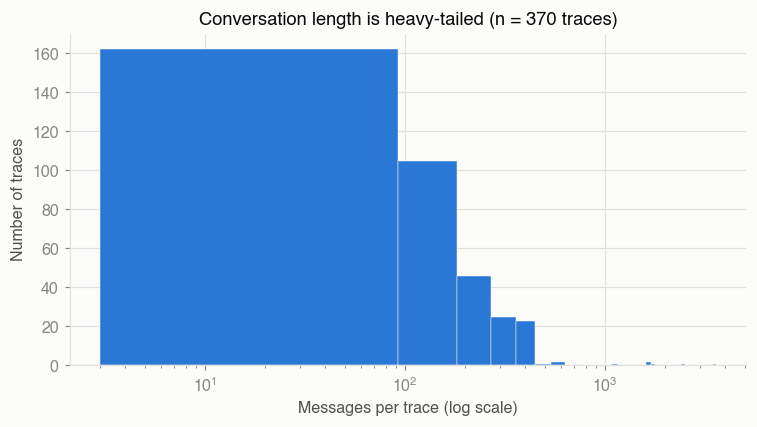

In [13]:
lens = pd.Series(n_msgs_per_row)
print("Messages-per-trace distribution:")
print(lens.describe())
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(lens, bins=40, color=atl.CATEGORICAL_PALETTE[0], edgecolor=atl.SURFACE, linewidth=0.3)
ax.set_xlabel("Messages per trace (log scale)")
ax.set_ylabel("Number of traces")
ax.set_xscale("log")
ax.set_title(f"Conversation length is heavy-tailed (n = {len(lens)} traces)")
fig.tight_layout()
fig.savefig(OUT / "figures" / "04_conversation_length_hist.png", dpi=150)
plt.show()

Recorded lengths range from 3 to 3,573 messages. The heavy right tail motivates medians and IQRs and the classifier's `log1p(n_messages)` feature. Counts measure recorded activity, not elapsed time or token-accurate cost.

## 5. Data Representation Strategy

Given the audit above, one flat DataFrame cannot represent this dataset faithfully. We
build **five base tables**, keyed by `row_id`, plus task/model aggregates. `row_id` is the 0..369 positional index into the raw snapshot, retained throughout the base tables so aggregates can be traced back through their grouping keys. All construction logic lives in
`agent_traces_lib.py` as small, named, independently callable functions — with later feature calculations shown here — so the same parsing is reused consistently across every later section instead of
being re-implemented (and potentially re-broken) per analysis.

| Table | Grain | Purpose |
|---|---|---|
| `row_df` | 1 row / trace (370) | Central fact table: original scalars + derived trace-shape summaries |
| `msg_df` | 1 row / message (~61.8k) | Role sequences, per-message length, position within trace |
| `toolcall_df` | 1 row / tool call (~30.8k) | Which tool, what arguments, call order — for tool-use and sequence analysis |
| `proxy_df` | 1 row / proxy request (~30.8k) | HTTP-style status codes only |
| `tooldef_df` | 1 row / tool definition (4 x 370 = 1,480) | What tools were *offered*, as opposed to *used* |
| `task_df` / `model_df` | 1 row / `task_id` or `model` | Aggregates for the hierarchy analysis in Section 11 |

We deliberately do **not** attempt to reconstruct a single fully-flattened
"long" table joining messages to tool calls to proxy requests: a tool call and its
corresponding proxy request(s) are not explicitly linked by any shared ID in the raw
data (there is no `tool_call_id` on `proxy_requests`), so forcing that join would
fabricate a relationship the data does not actually assert. This is documented as a
limitation in Section 21, not silently worked around.

In [14]:
row_df = atl.build_row_table(ds)
msg_df = atl.build_message_table(ds)
toolcall_df = atl.build_toolcall_table(ds)
proxy_df = atl.build_proxy_table(ds)
tooldef_df = atl.build_tooldef_table(ds)

for name, df in [("row_df", row_df), ("msg_df", msg_df), ("toolcall_df", toolcall_df),
                  ("proxy_df", proxy_df), ("tooldef_df", tooldef_df)]:
    print(f"{name:12s} shape={df.shape}")

row_df       shape=(370, 40)
msg_df       shape=(61851, 9)
toolcall_df  shape=(30757, 11)
proxy_df     shape=(30767, 3)
tooldef_df   shape=(1480, 6)


In [15]:
row_df.head(3)

,row_id,model,job,trial,task_id,status,reward,n_proxy_requests,n_messages,n_system_msgs,n_developer_msgs,n_user_msgs,n_assistant_msgs,n_tool_msgs,first_message_role,last_message_role,system_role_convention,n_tools_available,tool_names_available,n_tool_calls,n_malformed_tool_calls,n_task_complete_calls,tool_call_to_msg_ratio,n_assistant_with_reasoning,frac_assistant_with_reasoning,median_reasoning_len,total_reasoning_chars,n_assistant_blank_content,total_conversation_chars,approx_total_tokens,system_prompt_len,system_prompt_date,tools_definition_total_len,n_proxy_requests_parsed,n_proxy_200,n_proxy_429,n_proxy_503,n_proxy_other,has_rate_limit_events,success
0,0,model-orion,run-05,academysoftwarefoundation__rez-1__v9DA9Mr,academysoftwarefoundation__rez-1863,OK,1,25,61,1,0,1,25,34,system,assistant,system,4,"(bash, edit, read, write)",34,0,0,1.360000,24,0.960000,332.5,16177,23,260156,65039.00,2443,2026-06-10,999,25,25,0,0,0,False,1
1,1,model-cyan,run-07,aeon-toolkit__aeon-1767__UPkxiUL,aeon-toolkit__aeon-1767,WA,0,32,67,0,1,1,31,34,developer,assistant,developer,4,"(bash, edit, read, write)",34,0,0,1.096774,29,0.935484,661.0,38360,22,137995,34498.75,2443,2026-07-10,1033,32,32,0,0,0,False,0
2,2,model-cyan,run-01,aeon-toolkit__aeon-1767__ySVcdkZ,aeon-toolkit__aeon-1767,OK,1,46,101,1,0,1,46,53,system,assistant,system,4,"(bash, edit, read, write)",53,0,0,1.152174,43,0.934783,380.0,22298,37,144011,36002.75,2443,2026-06-12,1033,46,46,0,0,0,False,1


## 6. Data-Quality Analysis

We now run explicit reconciliation checks between the raw dataset and every derived
table, and report data-quality issues **as findings**, without silently "fixing" them.
Where a transformation *is* applied later in the notebook (e.g. treating a missing
`content` key as empty string), it is called out at the point of use.

In [16]:
report = atl.run_consistency_checks(ds, row_df, msg_df, toolcall_df, proxy_df)
report

,check,n_rows_checked,n_failures,passed
0,len(proxy_requests) == n_proxy_requests,370,0,True
1,exploded tool-call count == row-level n_tool_c...,370,0,True
2,trial column is unique per row,370,0,True
3,reward == 1{status == 'OK'} for every row,370,0,True
4,each job maps to exactly one model,15,0,True


In [17]:
report.to_csv(OUT / "data_audit" / "consistency_checks.csv", index=False)
assert report["passed"].all(), "Count or metadata reconciliation failed"
print("Five count/metadata checks pass; this does not establish transcript completeness.")
id_events = atl.audit_tool_ids(ds)
id_events.to_csv(OUT / "data_audit" / "tool_id_anomalies.csv", index=False)
print(id_events.groupby("kind").size().rename("events"))
print("Affected traces:", id_events.row_id.nunique())

Five count/metadata checks pass; this does not establish transcript completeness.


kind
orphan_result                  13
reused_call_id                  1
unanswered_nonterminal_call    12
unanswered_terminal_call       50
Name: events, dtype: int64
Affected traces: 67


### What the checks establish

The five count/metadata checks pass. The separate occurrence-aware ID audit finds 13 orphan results, 62 unanswered calls (50 terminal and 12 nonterminal), and one reused call ID (row 105), affecting 67 traces. The unanswered calls comprise 50 bash, six edit, four read, and two write calls. Terminal means the call occurs in the last recorded message; it is compatible with a cutoff, not proof of an expected stop. Pairing matches ordered occurrences of each ID, then separately checks whether results precede their paired calls; no ordering violations are detected in this snapshot. Orphan results and reused IDs remain unexplained. We do not label all affected traces corrupt or silently repair them.

### Reward is determined by status

In [18]:
ct = pd.crosstab(row_df["status"], row_df["reward"])
print(ct)
print(f"\nreward == 1{{status == 'OK'}} holds for {(row_df['reward'] == (row_df['status']=='OK').astype(int)).mean():.1%} of rows (i.e. all of them).")

reward    0    1
status          
IL       26    0
OK        0  218
TL        5    0
WA      121    0

reward == 1{status == 'OK'} holds for 100.0% of rows (i.e. all of them).


**Direct observation:** every `OK` row has `reward = 1`; every `WA`/`IL`/`TL` row has
`reward = 0`. There is no partial credit, no continuous or ordinal reward signal
hiding underneath — `reward` in this dataset is exactly a 0/1 re-encoding of
`status == "OK"`, and it carries **zero additional information** beyond `status`.
Consequently, everywhere this notebook analyzes "reward," it is equivalent to
analyzing binary success, and we use `status` (with its four levels) wherever more
resolution is useful — most importantly in Section 8's failure-mode analysis, where
collapsing `WA` / `IL` / `TL` into a single "reward = 0" bucket would erase real
structure, as the rest of the notebook shows.

### Unrecognized tool-call names (cause unresolved)

In [19]:
bad = toolcall_df[~toolcall_df["matched_known_tool"]]
print(f"{len(bad)} / {len(toolcall_df)} calls ({len(bad)/len(toolcall_df):.3%}) have unrecognized names.")
bad_view = bad.merge(row_df[["row_id", "model", "task_id", "status"]], on="row_id", validate="many_to_one")
print(bad_view[["row_id", "model", "task_id", "status", "n_arguments"]].to_string(index=False))
print("Recorded names and argument fragments are omitted from the publication view.")

18 / 30757 calls (0.059%) have unrecognized names.
 row_id       model                            task_id status  n_arguments
     42 model-orion                    ctfd__ctfd-2767     OK            1
     42 model-orion                    ctfd__ctfd-2767     OK            1
     62 model-flint encode__django-rest-framework-9360     IL            0
    158 model-flint         oceanparcels__parcels-2091     IL            1
    160 model-orion          opendatacube__odc-geo-124     WA            3
    182 model-orion         peopledoc__workalendar-373     WA            1
    272 model-flint                    pypa__pip-13065     IL            0
    272 model-flint                    pypa__pip-13065     IL            0
    298 model-delta         quantconnect__lean-cli-486     OK            1
    298 model-delta         quantconnect__lean-cli-486     OK            1
    298 model-delta         quantconnect__lean-cli-486     OK            1
    307 model-orion       rigetticomputing__pyqui

**Observation:** 18 calls have names outside the four declared tools and the `task_complete` sentinel, affecting 13 traces. Some resemble argument fragments or contain leading whitespace. A harness parsing problem is one possible explanation; the exporter and parser are unavailable, so the cause and intended action are unknown. We retain these calls with `matched_known_tool=False` rather than silently repairing them.

### Trace termination patterns

In [20]:
print(row_df["last_message_role"].value_counts())
print()
trunc = row_df[row_df["last_message_role"] == "tool"]
print(f"{len(trunc)} / {len(row_df)} traces end on a 'tool' message rather than an 'assistant' message")
print("(i.e. the recorded transcript stops immediately after a tool result, with no final")
print(" assistant turn; the reason is unverified):")
print(trunc[["row_id", "model", "job", "task_id", "status", "n_messages"]].to_string(index=False))

last_message_role
assistant    362
tool           8
Name: count, dtype: int64

8 / 370 traces end on a 'tool' message rather than an 'assistant' message
(i.e. the recorded transcript stops immediately after a tool result, with no final
 assistant turn; the reason is unverified):
 row_id       model    job                                              task_id status  n_messages
     25 model-delta run-03                         awslabs__cfn-python-lint-682     OK          25
     41 model-delta run-03                                      ctfd__ctfd-2333     WA          29
     76 model-orion run-05                   feature-engine__feature_engine-793     OK          41
     98 model-delta run-03 googlecloudplatform__cloud-sql-python-connector-1246     WA          29
    103 model-delta run-03                            gtalarico__pyairtable-262     OK          31
    174 model-orion run-05                           pdfminer__pdfminer.six-335     WA          42
    248 model-delta run-12 

Eight traces (2.2%) end on a tool message, without a subsequent assistant turn. Their causes are unknown; neither an export cutoff nor intentional termination can be established from this field. We retain them. No exclusion sensitivity analysis was performed. These endpoints are distinct from unanswered assistant calls, which the identifier audit reports separately.

### Missing values on scalar and nested-summary columns

In [21]:
missing_report = pd.DataFrame({
    "n_missing": row_df.isna().sum(),
    "pct_missing": (100 * row_df.isna().mean()).round(2),
}).query("n_missing > 0").sort_values("n_missing", ascending=False)
missing_report

,n_missing,pct_missing
median_reasoning_len,5,1.35


Raw scalar fields are complete in this snapshot. Derived missing values, such as a median over no nonblank reasoning strings, represent undefined summaries. Classifier features explicitly fill missing values with zero. This convention is transparent but can encode recording differences.

### Repeated identifiers and task identity

In [22]:
print("Duplicate trial identifiers:", row_df["trial"].duplicated().sum())
print("Distinct task_id values:", row_df["task_id"].nunique(), "across", len(row_df), "rows")
dup_tasks = row_df["task_id"].value_counts()
print("\ntask_id attempt-count distribution:")
print(dup_tasks.value_counts().sort_index().rename("n_task_ids_with_this_many_attempts"))

Duplicate trial identifiers: 0
Distinct task_id values: 253 across 370 rows

task_id attempt-count distribution:
count
1    161
2     72
3     16
4      3
5      1
Name: n_task_ids_with_this_many_attempts, dtype: int64


There are no duplicate `trial` identifiers; this does not constitute a full-record duplicate screen. Of 253 tasks, 161 (63.6%) have one attempt and 92 have multiple attempts. Unequal repeated measures can overweight some tasks in pooled summaries. We check whether repeated task IDs have identical user prompts; system prompts can vary across jobs.

In [23]:
user_msgs = []
for row in ds:
    um = next((m.get("content") for m in row["conversation"] if m.get("role") == "user"), None)
    user_msgs.append(um)
row_df["user_prompt"] = user_msgs
row_df["user_prompt_len"] = row_df["user_prompt"].str.len()

dup = row_df[row_df.duplicated("task_id", keep=False)]
n_inconsistent = dup.groupby("task_id")["user_prompt"].nunique().gt(1).sum()
print(f"task_ids with >1 attempt: {dup['task_id'].nunique()}")
print(f"...of which the user-facing task prompt text DIFFERS across attempts: {n_inconsistent}")
assert row_df.groupby("task_id").user_prompt.nunique().eq(1).all()
assert row_df.groupby("user_prompt").task_id.nunique().eq(1).all()
print("Task IDs and observed user-prompt strings map one-to-one in this snapshot.")

task_ids with >1 attempt: 92
...of which the user-facing task prompt text DIFFERS across attempts: 0
Task IDs and observed user-prompt strings map one-to-one in this snapshot.


In [24]:
row_df.drop(columns=["user_prompt", "final_msg_text"], errors="ignore").to_parquet(OUT / "derived_tables" / "row_level.parquet")
msg_df.to_parquet(OUT / "derived_tables" / "messages.parquet")
toolcall_df.to_parquet(OUT / "derived_tables" / "tool_calls.parquet")
proxy_df.to_parquet(OUT / "derived_tables" / "proxy_requests.parquet")
tooldef_df.to_parquet(OUT / "derived_tables" / "tool_definitions.parquet")
print("Checkpoint tables written to analysis_outputs/derived_tables/")

Checkpoint tables written to analysis_outputs/derived_tables/


## 7. Baseline Exploratory Analysis

**Question:** before testing any hypothesis, what does the raw shape of the dataset
look like across its core dimensions? **Why:** this section exists to build
correct intuition and to surface any gross imbalance that later sections must account
for (e.g. an uneven `model` x `job` design). **Method:** counts, distributions, and
simple cross-tabulations — no modelling yet.

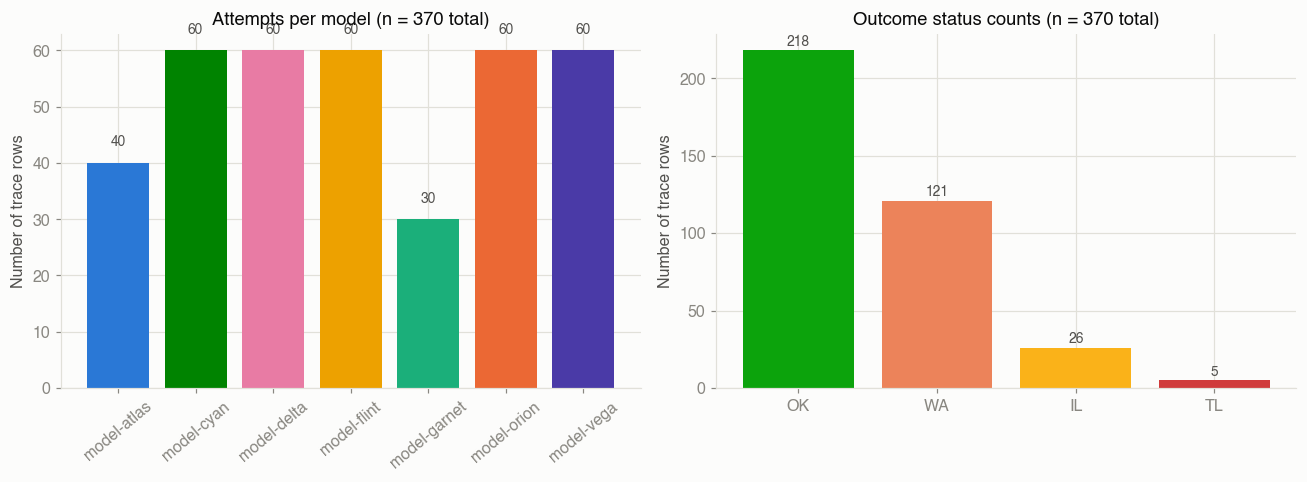

model
model-atlas     40
model-cyan      60
model-delta     60
model-flint     60
model-garnet    30
model-orion     60
model-vega      60
Name: count, dtype: int64

status
OK    218
WA    121
IL     26
TL      5
Name: count, dtype: int64


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

model_counts = row_df["model"].value_counts().reindex(atl.MODEL_ORDER)
axes[0].bar(model_counts.index, model_counts.values,
            color=[atl.MODEL_COLORS[m] for m in model_counts.index])
axes[0].set_title("Attempts per model (n = 370 total)")
axes[0].set_ylabel("Number of trace rows")
axes[0].tick_params(axis="x", rotation=40)

status_counts = row_df["status"].value_counts().reindex(atl.STATUS_ORDER)
axes[1].bar(status_counts.index, status_counts.values,
            color=[atl.STATUS_COLORS[s] for s in status_counts.index])
axes[1].set_title("Outcome status counts (n = 370 total)")
axes[1].set_ylabel("Number of trace rows")
for ax, counts in zip(axes, [model_counts, status_counts]):
    for i, v in enumerate(counts.values):
        ax.text(i, v + 3, str(v), ha="center", fontsize=9, color=atl.INK_SECONDARY)

fig.tight_layout()
fig.savefig(OUT / "figures" / "07_model_status_counts.png", dpi=150)
plt.show()
print(model_counts)
print()
print(status_counts)

**Observation:** the design is unbalanced by construction — `model-atlas` (40) and
`model-garnet` (30) have fewer attempts than the other five models (60 each), and
`status` is dominated by `OK` (218, 58.9%) and `WA` (121, 32.7%), with `IL` (26, 7.0%)
and `TL` (5, 1.4%) much rarer. Any model-level comparison must keep these unequal
sample sizes in mind (visible as uncertainty bands in Section 8), and any model of
`TL` in particular has only 5 positive examples to learn from — far too few for a
reliable standalone estimate, which is why Section 8 treats `TL` primarily
descriptively rather than statistically.

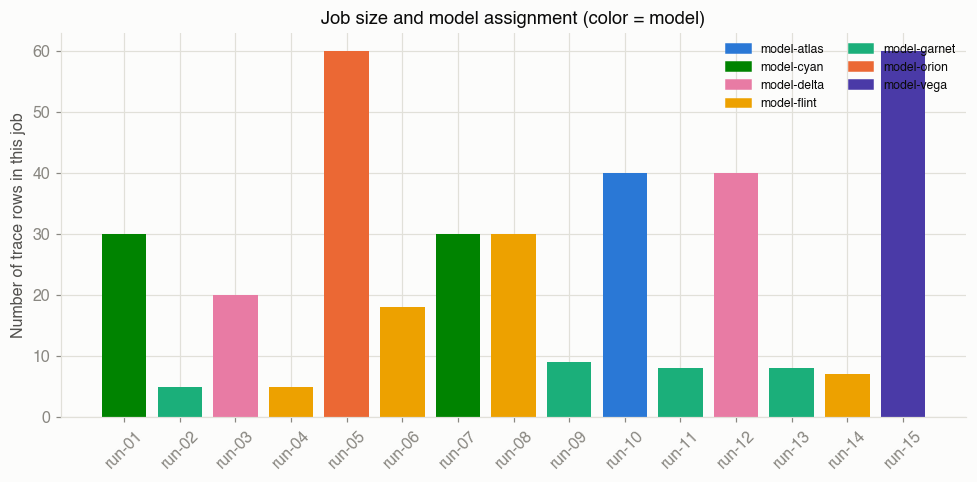


Every job maps to exactly one model: True
       model    job  n
 model-atlas run-10 40
  model-cyan run-01 30
  model-cyan run-07 30
 model-delta run-03 20
 model-delta run-12 40
 model-flint run-04  5
 model-flint run-06 18
 model-flint run-08 30
 model-flint run-14  7
model-garnet run-02  5
model-garnet run-09  9
model-garnet run-11  8
model-garnet run-13  8
 model-orion run-05 60
  model-vega run-15 60


In [26]:
fig, ax = plt.subplots(figsize=(9, 4.5))
job_order = row_df.groupby("job")["model"].first().sort_index().index
for j in job_order:
    sub = row_df[row_df.job == j]
    m = sub["model"].iloc[0]
    ax.bar(j, len(sub), color=atl.MODEL_COLORS[m])
ax.set_title("Job size and model assignment (color = model)")
ax.set_ylabel("Number of trace rows in this job")
ax.tick_params(axis="x", rotation=45)
handles = [plt.Rectangle((0,0),1,1, color=atl.MODEL_COLORS[m]) for m in atl.MODEL_ORDER]
ax.legend(handles, atl.MODEL_ORDER, loc="upper right", ncol=2, fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "figures" / "07_job_sizes_by_model.png", dpi=150)
plt.show()

job_model = row_df.groupby("job")["model"].nunique()
print(f"\nEvery job maps to exactly one model: {(job_model == 1).all()}")
print(row_df.groupby(["model","job"]).size().rename("n").reset_index().to_string(index=False))

Every job maps to one model label; some labels span several jobs. Job is treated as an observed execution batch, with potentially different run conditions. Differences between jobs may also reflect unequal task assignments.

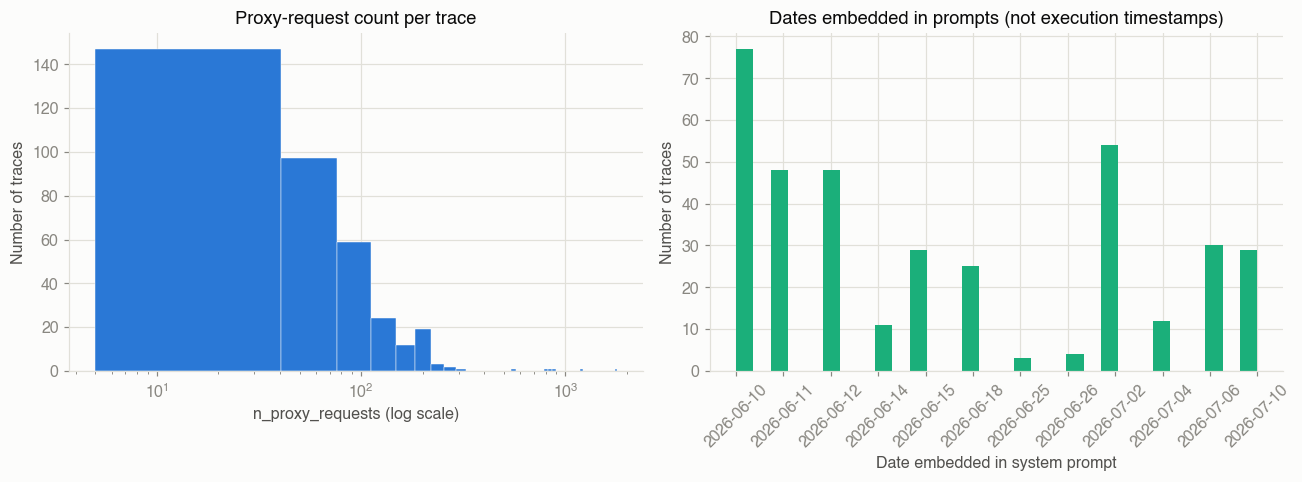

count     370.000000
mean       83.154054
std       141.072933
min         5.000000
25%        26.000000
50%        50.500000
75%        99.750000
max      1786.000000
Name: n_proxy_requests, dtype: float64

Date range: 2026-06-10 to 2026-07-10


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(row_df["n_proxy_requests"], bins=50, color=atl.CATEGORICAL_PALETTE[0], edgecolor=atl.SURFACE, linewidth=0.3)
axes[0].set_xlabel("n_proxy_requests (log scale)")
axes[0].set_ylabel("Number of traces")
axes[0].set_xscale("log")
axes[0].set_title("Proxy-request count per trace")

axes[1].hist(row_df["system_prompt_date"].sort_values(), bins=30, color=atl.CATEGORICAL_PALETTE[4])
axes[1].set_xlabel("Date embedded in system prompt")
axes[1].set_ylabel("Number of traces")
axes[1].set_title("Dates embedded in prompts (not execution timestamps)")
axes[1].tick_params(axis="x", rotation=45)

fig.tight_layout()
fig.savefig(OUT / "figures" / "07_proxy_and_dates.png", dpi=150)
plt.show()

print(row_df["n_proxy_requests"].describe())
print()
print("Date range:", row_df["system_prompt_date"].min(), "to", row_df["system_prompt_date"].max())

Proxy-request counts span 5–1,786 (median 50.5). Embedded prompt dates range from 2026-06-10 to 2026-07-10. These dates co-vary with job and role convention in the cyan comparison. They are not independent observations of execution time.

### Conversation shape: role counts, tool volume, and reasoning-field coverage

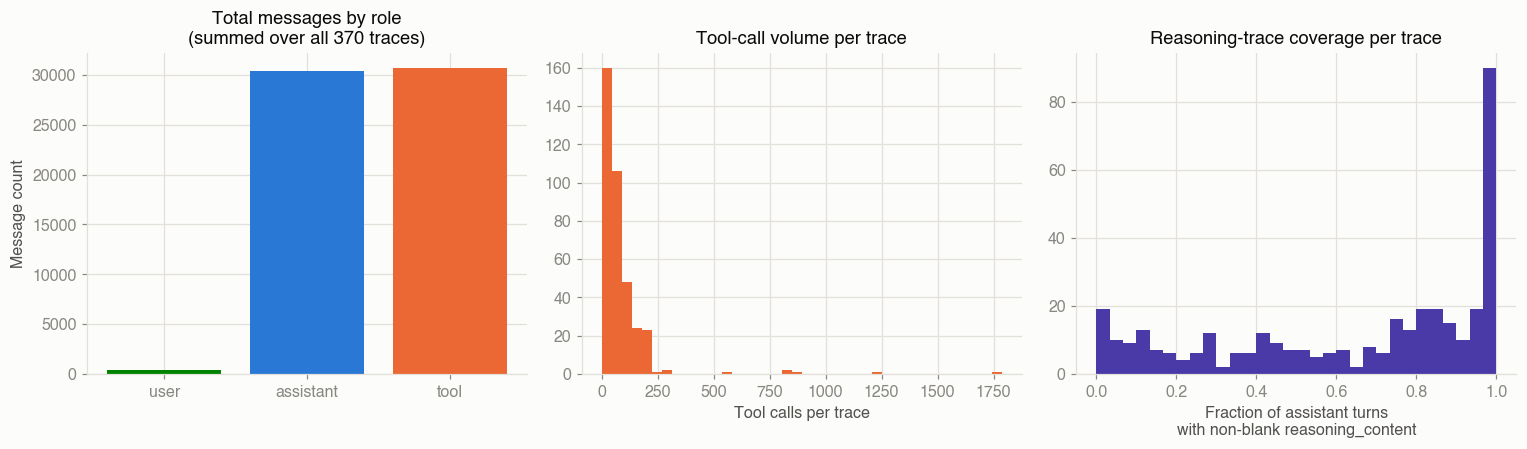

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

role_cols = ["n_user_msgs", "n_assistant_msgs", "n_tool_msgs"]
role_totals = row_df[role_cols].sum()
axes[0].bar(["user", "assistant", "tool"], role_totals.values,
            color=[atl.CATEGORICAL_PALETTE[i] for i in (1, 0, 5)])
axes[0].set_title("Total messages by role\n(summed over all 370 traces)")
axes[0].set_ylabel("Message count")

axes[1].hist(row_df["n_tool_calls"], bins=40, color=atl.CATEGORICAL_PALETTE[5])
axes[1].set_xlabel("Tool calls per trace")
axes[1].set_title("Tool-call volume per trace")

axes[2].hist(row_df["frac_assistant_with_reasoning"].dropna(), bins=30, color=atl.CATEGORICAL_PALETTE[6])
axes[2].set_xlabel("Fraction of assistant turns\nwith non-blank reasoning_content")
axes[2].set_title("Reasoning-trace coverage per trace")

fig.tight_layout()
fig.savefig(OUT / "figures" / "07_conversation_shape.png", dpi=150)
plt.show()

In [29]:
by_model_reasoning = row_df.groupby("model")["frac_assistant_with_reasoning"].agg(["mean", "median", "count"])
print("Fraction of assistant turns carrying non-blank reasoning_content, by model:")
print(by_model_reasoning.reindex(atl.MODEL_ORDER).round(3))

Fraction of assistant turns carrying non-blank reasoning_content, by model:
               mean  median  count
model                             
model-atlas   0.568   0.510     40
model-cyan    0.737   0.772     60
model-delta   0.159   0.090     60
model-flint   1.000   1.000     60
model-garnet  0.976   1.000     30
model-orion   0.873   0.877     60
model-vega    0.316   0.294     60


The presence of nonblank `reasoning_content` varies substantially by model label (mean per-trace assistant-turn coverage ranges from about 0.16 to 1.00). This may reflect model behaviour, configuration, or what an integration records; the dataset cannot separate these explanations. We analyze only presence and length, without interpreting the text as a faithful account of internal reasoning or as a reasoning-quality measure.

In [30]:
tab = row_df.groupby("model").apply(lambda d: (d["frac_assistant_with_reasoning"] > 0).mean())
print("Fraction of TRACES (not turns) with at least some non-blank reasoning_content, by model:")
print(tab.reindex(atl.MODEL_ORDER).round(3))

Fraction of TRACES (not turns) with at least some non-blank reasoning_content, by model:
model
model-atlas     1.000
model-cyan      1.000
model-delta     0.967
model-flint     1.000
model-garnet    1.000
model-orion     1.000
model-vega      0.950
dtype: float64


## 8. Outcomes and evaluation conditions

**Question:** which outcome patterns are visible, and what prevents a capability interpretation? **Method:** status/count summaries, raw model rates with descriptive intervals, a repository-family variance decomposition, task-overlap summaries, and the existing paired cyan job comparison. The recorded labels are observations; proposed meanings of IL and TL are interpretations.

In [31]:
stat_by_status = row_df.groupby("status")[["n_proxy_requests", "n_messages"]].describe().T
print(stat_by_status.round(1))

status                     IL      OK      TL     WA
n_proxy_requests count   26.0   218.0     5.0  121.0
                 mean   152.9    69.0   581.2   73.1
                 std     50.2   123.0   748.4   52.8
                 min    100.0     6.0    87.0    5.0
                 25%    100.0    19.0    88.0   31.0
                 50%    187.5    41.0   100.0   66.0
                 75%    200.0    72.0   845.0   94.0
                 max    200.0  1213.0  1786.0  290.0
n_messages       count   26.0   218.0     5.0  121.0
                 mean   307.8   139.3  1161.8  146.0
                 std    101.4   245.8  1498.0  108.0
                 min    201.0    13.0   169.0    3.0
                 25%    201.0    37.0   177.0   66.0
                 50%    375.0    85.0   199.0  133.0
                 75%    401.8   145.0  1691.0  193.0
                 max    411.0  2427.0  3573.0  581.0


In [32]:
il = row_df[row_df.status == "IL"]
print("IL rows: n_proxy_requests value counts")
print(il["n_proxy_requests"].value_counts().sort_index())
print()
print("IL rows: n_proxy_requests cap, by job")
print(il.groupby("job")["n_proxy_requests"].agg(["min", "max", "count"]))

IL rows: n_proxy_requests value counts
n_proxy_requests
100    12
175     1
200    13
Name: count, dtype: int64

IL rows: n_proxy_requests cap, by job
        min  max  count
job                    
run-04  200  200      1
run-06  100  175     13
run-08  200  200      9
run-10  200  200      2
run-15  200  200      1


IL request counts are 100, 175, or 200 and cluster by job. This is consistent with a request or iteration budget, but neither the acronym nor its triggering rule is documented. TL counts vary from 87 to 1,786; a wall-clock limit is a plausible interpretation. No timestamps or grader logs verify it. Accordingly, taxonomy labels below preserve the recorded statuses rather than asserting cutoff mechanisms.

### 8.2 Binary reward and four-level status

In [33]:
print(row_df.groupby("status").n_proxy_requests.median().rename("median_requests"))
print("Reward is binary; status retains four recorded outcome categories.")

status
IL    187.5
OK     41.0
TL    100.0
WA     66.0
Name: median_requests, dtype: float64
Reward is binary; status retains four recorded outcome categories.


### 8.3 Model-level reward: a first look, and an immediate confounding warning

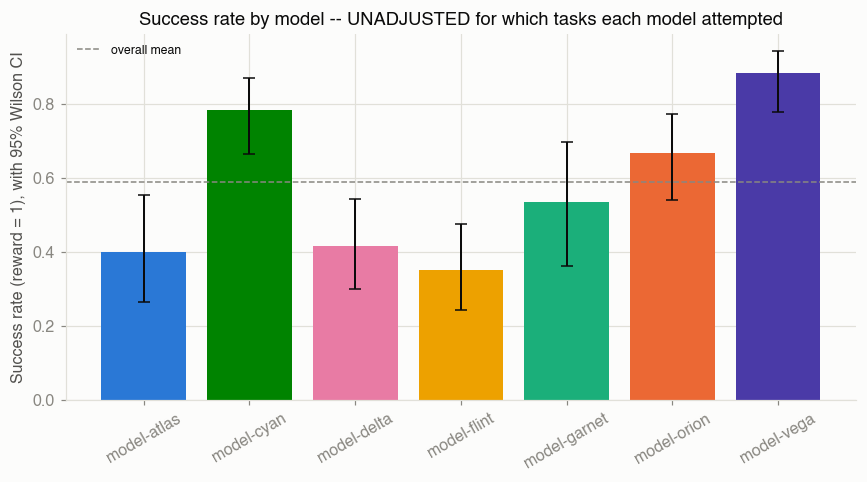

              n_trials  n_distinct_tasks  mean_reward
model                                                
model-atlas         40                40     0.400000
model-cyan          60                42     0.783333
model-delta         60                59     0.416667
model-flint         60                55     0.350000
model-garnet        30                28     0.533333
model-orion         60                60     0.666667
model-vega          60                60     0.883333


In [34]:
model_df = atl.build_model_level_table(row_df)
model_df_display = model_df.set_index("model").reindex(atl.MODEL_ORDER)

fig, ax = plt.subplots(figsize=(8, 4.5))
# Wilson score interval for a proportion -- more appropriate than a normal
# approximation at these small, unequal sample sizes (some n as low as 30).
from scipy import stats as sstats

def wilson_ci(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    phat = k / n
    denom = 1 + z**2 / n
    center = (phat + z**2 / (2*n)) / denom
    half = (z * np.sqrt(phat*(1-phat)/n + z**2/(4*n**2))) / denom
    return (center - half, center + half)

ks = (model_df_display["mean_reward"] * model_df_display["n_trials"]).round().astype(int)
ns = model_df_display["n_trials"]
cis = [wilson_ci(k, n) for k, n in zip(ks, ns)]
lo = np.array([c[0] for c in cis])
hi = np.array([c[1] for c in cis])
means = model_df_display["mean_reward"].values

ax.bar(model_df_display.index, means, color=[atl.MODEL_COLORS[m] for m in model_df_display.index])
ax.errorbar(model_df_display.index, means, yerr=[means-lo, hi-means], fmt="none",
            ecolor=atl.INK_PRIMARY, elinewidth=1.3, capsize=4)
ax.axhline(row_df["reward"].mean(), color=atl.INK_MUTED, linestyle="--", linewidth=1, label="overall mean")
ax.set_ylabel("Success rate (reward = 1), with 95% Wilson CI")
ax.set_title("Success rate by model -- UNADJUSTED for which tasks each model attempted")
ax.tick_params(axis="x", rotation=30)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "figures" / "08_model_success_rate_raw.png", dpi=150)
plt.show()

print(model_df_display[["n_trials", "n_distinct_tasks", "mean_reward"]])

Raw rates range from 35% to about 88%. Wilson intervals summarize binomial sampling uncertainty under an independent-attempt model; repeated tasks and shared jobs violate that simple model, so these are descriptive intervals, not task-cluster-adjusted uncertainty. Unequal task assignment prevents reading the chart as a controlled model ranking.

### 8.4 Repository-family outcome heterogeneity

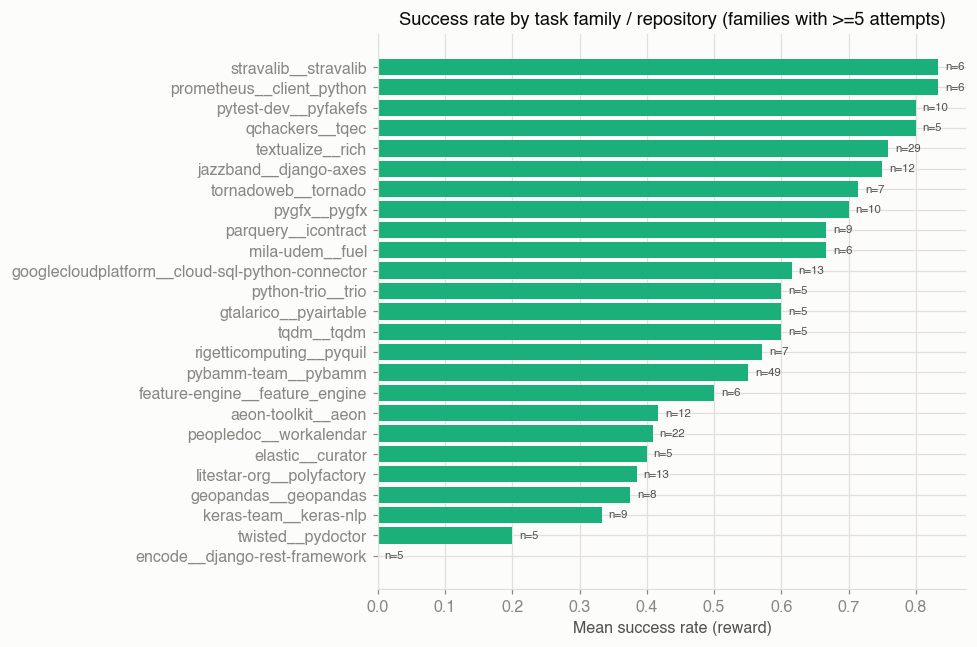

Overall reward variance:                    0.2427
Between-task-family variance component:     0.0620
Descriptive between-family share of variance: 25.5%


In [35]:
task_df = atl.build_task_level_table(row_df)

fam_re = re.compile(r"^(.*)-\d+$")
row_df["task_family"] = row_df["task_id"].apply(lambda t: (fam_re.match(t).group(1) if fam_re.match(t) else t))

fam_stats = (row_df.groupby("task_family")
             .agg(n=("row_id", "size"), mean_reward=("reward", "mean"))
             .query("n >= 5")
             .sort_values("mean_reward"))

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(fam_stats.index, fam_stats["mean_reward"], color=atl.CATEGORICAL_PALETTE[4])
ax.set_xlabel("Mean success rate (reward)")
ax.set_title("Success rate by task family / repository (families with >=5 attempts)")
for i, (n, v) in enumerate(zip(fam_stats["n"], fam_stats["mean_reward"])):
    ax.text(v + 0.01, i, f"n={n}", va="center", fontsize=7.5, color=atl.INK_SECONDARY)
fig.tight_layout()
fig.savefig(OUT / "figures" / "08_task_family_success.png", dpi=150)
plt.show()

overall_var = row_df["reward"].var()
fam_all = row_df.groupby("task_family")["reward"].agg(["mean", "size"])
between_fam_component = ((fam_all["mean"] - row_df["reward"].mean())**2 * fam_all["size"]).sum() / (len(row_df) - 1)
print(f"Overall reward variance:                    {overall_var:.4f}")
print(f"Between-task-family variance component:     {between_fam_component:.4f}")
print(f"Descriptive between-family share of variance: {between_fam_component/overall_var:.1%}")

The descriptive between-family component is roughly one quarter of total outcome variance. This summarizes variation among observed group means, including sampling noise and model/job composition; it does not identify a causal effect of repository or independently measure task difficulty. Repository family is derived from the task ID, not from outcomes. The result motivates examining overlap rather than interpreting raw model rates as capability differences.

### 8.5 Task overlap across jobs of the same model

In [36]:
records = []
for model in row_df["model"].unique():
    sub = row_df[row_df.model == model]
    jobs = sorted(sub["job"].unique())
    if len(jobs) < 2:
        continue
    task_sets = {j: set(sub[sub.job == j]["task_id"]) for j in jobs}
    for i in range(len(jobs)):
        for k in range(i + 1, len(jobs)):
            a, b = jobs[i], jobs[k]
            overlap = len(task_sets[a] & task_sets[b])
            records.append({
                "model": model, "job_a": a, "job_b": b,
                "n_tasks_a": len(task_sets[a]), "n_tasks_b": len(task_sets[b]),
                "n_shared_tasks": overlap,
            })
overlap_df = pd.DataFrame(records)
print(overlap_df.to_string(index=False))

       model  job_a  job_b  n_tasks_a  n_tasks_b  n_shared_tasks
  model-cyan run-01 run-07         30         30              18
 model-delta run-03 run-12         20         40               1
 model-flint run-04 run-06          5         18               0
 model-flint run-04 run-08          5         29               1
 model-flint run-04 run-14          5          7               0
 model-flint run-06 run-08         18         29               3
 model-flint run-06 run-14         18          7               0
 model-flint run-08 run-14         29          7               0
model-garnet run-02 run-09          5          9               0
model-garnet run-02 run-11          5          8               0
model-garnet run-02 run-13          5          8               0
model-garnet run-09 run-11          9          8               0
model-garnet run-09 run-13          9          8               0
model-garnet run-11 run-13          8          8               2


**Direct observation:** for `model-flint`, `model-garnet`, and `model-delta`'s two job
pairs, task overlap across jobs of the same model is **near zero** — these jobs
attempted almost entirely disjoint task sets. **This means the large job-to-job reward
swings we saw in Section 7 for those models (e.g. `model-flint`: 11%–86% success across
its four jobs) are confounded with task-difficulty differences and cannot, on their
own, be read as evidence of model instability.**

`model-cyan` is the one exception: `run-01` and `run-07` share **18 of their 30 tasks
each**, which lets us run a genuine matched (paired) comparison — the same model, the
same tasks, two different jobs.

### 8.6 A matched comparison: `model-cyan`, same 18 tasks, `run-01` vs. `run-07`

In [37]:
sub = row_df[row_df.model == "model-cyan"]
r01 = sub[sub.job == "run-01"].set_index("task_id")
r07 = sub[sub.job == "run-07"].set_index("task_id")
shared = r01.index.intersection(r07.index)

paired = pd.DataFrame({
    "reward_run01": r01.loc[shared, "reward"],
    "reward_run07": r07.loc[shared, "reward"],
    "role_run01": r01.loc[shared, "system_role_convention"],
    "role_run07": r07.loc[shared, "system_role_convention"],
    "date_run01": r01.loc[shared, "system_prompt_date"],
    "date_run07": r07.loc[shared, "system_prompt_date"],
})
print(f"n shared tasks: {len(paired)}")
print(f"run-01 success rate on these {len(paired)} tasks: {paired['reward_run01'].mean():.1%}  (role convention: {paired['role_run01'].iloc[0]}, dates {paired['date_run01'].min()}..{paired['date_run01'].max()})")
print(f"run-07 success rate on these {len(paired)} tasks: {paired['reward_run07'].mean():.1%}  (role convention: {paired['role_run07'].iloc[0]}, dates {paired['date_run07'].min()}..{paired['date_run07'].max()})")

both_ok = int(((paired.reward_run01 == 1) & (paired.reward_run07 == 1)).sum())
only_01 = int(((paired.reward_run01 == 1) & (paired.reward_run07 == 0)).sum())
only_07 = int(((paired.reward_run01 == 0) & (paired.reward_run07 == 1)).sum())
both_fail = int(((paired.reward_run01 == 0) & (paired.reward_run07 == 0)).sum())
print(f"\n2x2 (discordant pairs matter most): both_OK={both_ok}  only_run01_OK={only_01}  only_run07_OK={only_07}  both_fail={both_fail}")

# Exact sign test on the discordant pairs (McNemar-style): under the null that
# a switch is equally likely to go either direction, P(7 out of 7 one-sided).
n_discordant = only_01 + only_07
p_value = sstats.binomtest(only_01, n_discordant, p=0.5, alternative="two-sided").pvalue if n_discordant > 0 else np.nan
print(f"\nDiscordant pairs: {n_discordant} (all {only_01} went run-01-OK -> run-07-fail, {only_07} went the other way)")
print(f"Exact two-sided sign-test p-value on the discordant pairs: {p_value:.4f}")

n shared tasks: 18
run-01 success rate on these 18 tasks: 94.4%  (role convention: system, dates 2026-06-12..2026-06-12)
run-07 success rate on these 18 tasks: 55.6%  (role convention: developer, dates 2026-07-04..2026-07-10)

2x2 (discordant pairs matter most): both_OK=10  only_run01_OK=7  only_run07_OK=0  both_fail=1

Discordant pairs: 7 (all 7 went run-01-OK -> run-07-fail, 0 went the other way)
Exact two-sided sign-test p-value on the discordant pairs: 0.0156


On 18 common tasks, cyan run-01 has 17 successes and run-07 has 10. Seven pairs disagree, all in the same direction; the exact two-sided sign test gives p=0.015625. This is a paired **job** comparison with task identity held fixed.

Role convention and embedded prompt date differ together with job. Other unobserved conditions may also differ. The comparison identifies an observed outcome gap, not its cause or a role-convention effect. The exploratory p-value is unadjusted for multiple comparisons.

### 8.7 Outcome agreement in repeated model/task groups

In [38]:
rep = row_df[row_df.duplicated(["model", "task_id"], keep=False)]
rep_summary = (rep.groupby(["model", "task_id"])["reward"]
               .agg(n="size", mean_reward="mean", std_reward="std")
               .reset_index())
n_inconsistent = int((rep_summary["std_reward"] > 0).sum())
print(f"(model, task_id) pairs with >1 attempt: {len(rep_summary)}")
print(f"...of which the repeated attempts DISAGREE on the outcome (one succeeds, one fails): {n_inconsistent} ({n_inconsistent/len(rep_summary):.1%})")
print()
print(rep_summary.sort_values("std_reward", ascending=False).head(10).to_string(index=False))
repeat_jobs = rep.groupby(["model", "task_id"]).job.nunique()
print("Repeated groups spanning multiple jobs:", int((repeat_jobs > 1).sum()))
rep_summary["n_jobs"] = rep_summary.set_index(["model", "task_id"]).index.map(repeat_jobs)
rep_summary.to_csv(OUT / "derived_tables" / "repeated_model_task_groups.csv", index=False)
print("Within-job repeated groups:")
print(rep_summary[rep_summary.n_jobs == 1].to_string(index=False))

(model, task_id) pairs with >1 attempt: 26
...of which the repeated attempts DISAGREE on the outcome (one succeeds, one fails): 8 (30.8%)

       model                               task_id  n  mean_reward  std_reward
  model-cyan               aeon-toolkit__aeon-1767  2          0.5    0.707107
  model-cyan         litestar-org__polyfactory-472  2          0.5    0.707107
 model-delta               parquery__icontract-297  2          0.5    0.707107
  model-cyan                python-trio__trio-3197  2          0.5    0.707107
  model-cyan               pybamm-team__pybamm-612  2          0.5    0.707107
  model-cyan opensearch-project__opensearch-py-394  2          0.5    0.707107
  model-cyan               pybamm-team__pybamm-971  2          0.5    0.707107
  model-cyan         litestar-org__polyfactory-468  2          0.5    0.707107
  model-cyan              stravalib__stravalib-503  2          1.0    0.000000
model-garnet    encode__django-rest-framework-9455  2          0.0    0

Within-job repeated groups:
      model                 task_id  n  mean_reward  std_reward  n_jobs
model-flint pybamm-team__pybamm-612  2          0.0         0.0       1


Eight of 26 repeated model/task groups disagree on binary outcome (30.8%). Twenty-five of the 26 span different jobs; the single within-job repeated group contains two failures. Seven of the eight disagreements are the cyan job flips above. This is largely **cross-job variation**, not an estimate of irreducible randomness under a fixed configuration. Controlled identical-condition repeats would be needed to separate stochastic variation from systematic job differences.

## 9. Conversation-Trace Analysis

**Question:** beyond simple length, what does the internal shape of a trace look like,
and does the agent's own final message reliably signal whether it actually succeeded?
**Why:** Section 4 established that every trace is a single user turn followed by an
autonomous agent loop — this section characterizes that loop itself. **Method:**
role-position features already built into `row_df`, plus a targeted rule-based text
scan of the final assistant message (deliberately simple and auditable, not an ML
classifier, since the question is narrow: does the message *contain* a
success-claiming phrase).

### 9.1 Blank-content assistant turns and pure-tool-call turns

In [39]:
frac_blank = (row_df["n_assistant_blank_content"] / row_df["n_assistant_msgs"].replace(0, np.nan))
print("Fraction of assistant turns with no text content (pure tool-call turns), overall:")
print(frac_blank.describe())
print()
print("By status:")
print(frac_blank.groupby(row_df["status"]).describe()[["mean", "50%"]])

Fraction of assistant turns with no text content (pure tool-call turns), overall:
count    370.000000
mean       0.844630
std        0.192449
min        0.142857
25%        0.751689
50%        0.941176
75%        0.986970
max        1.000000
dtype: float64

By status:
            mean       50%
status                    
IL      0.937471  0.980000
OK      0.801972  0.875000
TL      1.000000  1.000000
WA      0.895115  0.977099


Mean per-trace blank assistant-content shares rise from 80.2% (OK) to 89.5% (WA), 93.7% (IL), and 100% (TL). These per-trace means differ from the message-weighted missing-key percentage in Section 4. They describe recorded text availability and may reflect termination and recording conventions as well as agent behaviour.

### 9.2 Does final-message success language distinguish outcomes?

In [40]:
SUCCESS_PAT = re.compile(
    r"(all tests pass|tests? (now )?pass(es|ing)?|task (is )?complete|successfully|"
    r"task is done|fix(ed)? the (issue|bug)|resolves? the issue|issue (is )?resolved)",
    re.I,
)

final_text, self_reports = [], []
for row in ds:
    assistant_msgs = [m for m in row["conversation"] if m.get("role") == "assistant"]
    final = (assistant_msgs[-1].get("content") if assistant_msgs else "") or ""
    final_text.append(final)
    self_reports.append(bool(SUCCESS_PAT.search(final[-800:])))

row_df["final_msg_text"] = final_text
row_df["final_msg_has_text"] = row_df["final_msg_text"].str.strip().str.len().gt(0)
row_df["self_reports_success"] = self_reports

print("Does the final assistant message contain ANY text at all, by status?")
print(pd.crosstab(row_df["status"], row_df["final_msg_has_text"], normalize="index").round(3))

Does the final assistant message contain ANY text at all, by status?
final_msg_has_text  False  True 
status                          
IL                  0.885  0.115
OK                  0.073  0.927
TL                  1.000  0.000
WA                  0.140  0.860


The last assistant message has nonblank text in 92.7% of OK and 86.0% of WA traces, compared with 11.5% of IL and none of TL. This is compatible with the proposed cutoff interpretation, but does not confirm it. For tool-ending traces the last assistant message may precede the terminal tool result.

In [41]:
print("Among traces that DO end with text, does that text claim success (simple keyword scan)?")
has_text = row_df[row_df["final_msg_has_text"]]
print(pd.crosstab(has_text["status"], has_text["self_reports_success"], normalize="index").round(3))
print()
print("Self-report-positive rate, OK vs WA (restricted to traces with a final text message):")
print(has_text.groupby("status")["self_reports_success"].mean().round(3))

Among traces that DO end with text, does that text claim success (simple keyword scan)?
self_reports_success  False  True 
status                            
IL                    0.667  0.333
OK                    0.515  0.485
WA                    0.462  0.538

Self-report-positive rate, OK vs WA (restricted to traces with a final text message):
status
IL    0.333
OK    0.485
WA    0.538
Name: self_reports_success, dtype: float64


**Weak/null result:** among traces whose last assistant message contains text, the fixed regex flags success language in roughly 49% of OK and 54% of WA attempts. The motivating anecdote—confident summaries from both a successful and failed cyan attempt—does not translate into clear separation in this screen.

No equivalence test or uncertainty analysis was performed. The conclusion concerns this regex and this population, not all semantic confidence measures. Final-message language should not substitute for external outcome verification on the strength of these results.

### 9.3 Trace summaries by status

In [42]:
shape_cols = ["n_messages", "n_tool_calls", "n_assistant_msgs", "median_reasoning_len"]
summary = row_df.groupby("status")[shape_cols].median().reindex(atl.STATUS_ORDER)
summary.columns = [c + "_median" for c in shape_cols]
print(summary.round(1))

        n_messages_median  n_tool_calls_median  n_assistant_msgs_median  median_reasoning_len_median
status                                                                                              
OK                   85.0                 42.0                     39.5                        316.0
WA                  133.0                 65.0                     66.0                        388.0
IL                  375.0                187.0                    187.0                        113.0
TL                  199.0                 99.0                     99.0                        547.0


## 10. Proxy-Request and Tool-Use Analysis

**Question:** what do proxy requests and tool calls reveal as first-class behavioural
signals? **Why:** these are the only "actions" the agent actually takes on the
environment -- everything else in the trace is commentary around them. **Method:** the
`proxy_df` and `toolcall_df` exploded tables from Section 5, aggregated by outcome.

### 10.1 Proxy-request status codes: what actually shows up

In [43]:
print("Proxy request HTTP-style status codes, across all ~30.8k requests:")
print(proxy_df["status"].value_counts())
print()
print(f"Rows with >=1 rate-limit (429) response: {row_df['has_rate_limit_events'].sum()} / {len(row_df)}")

Proxy request HTTP-style status codes, across all ~30.8k requests:
status
200    30444
429      322
503        1
Name: count, dtype: int64

Rows with >=1 rate-limit (429) response: 29 / 370


The proxy log contains status codes without timestamps, methods, or endpoints. A recorded 429 occurs in 29/370 traces, and a 503 occurs in one trace. These HTTP-style codes are consistent with throttling and unavailability, but do not reveal request timing or agent recovery. We next compare the existing per-trace summaries.

In [44]:
rl = row_df.groupby("has_rate_limit_events").agg(
    n=("row_id", "size"),
    success_rate=("reward", "mean"),
    median_n_proxy_requests=("n_proxy_requests", "median"),
)
print(rl)
print()
print("Status breakdown among rate-limited traces:")
print(row_df[row_df.has_rate_limit_events]["status"].value_counts())

                         n  success_rate  median_n_proxy_requests
has_rate_limit_events                                            
False                  341      0.598240                     57.0
True                    29      0.482759                     30.0

Status breakdown among rate-limited traces:
status
WA    15
OK    14
Name: count, dtype: int64


Traces with a recorded 429 have 48.3% success (n=29), versus 59.8% without (n=341); their median request count is also lower. These summaries do not reveal retry timing or prove that throttling caused termination. Task/job differences may contribute. With few affected traces and no timestamps, this remains a descriptive association.

### 10.2 Tool mix by outcome

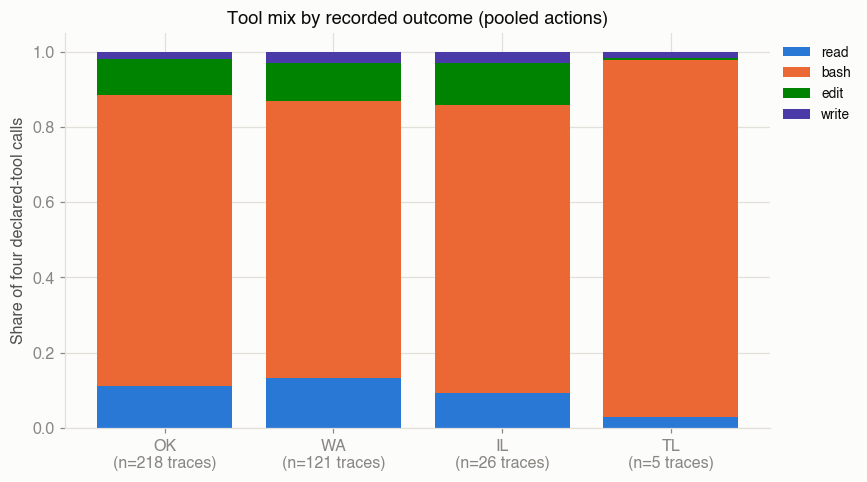

name     read   bash   edit  write
status                            
OK      0.110  0.774  0.096  0.019
WA      0.133  0.735  0.102  0.029
IL      0.093  0.764  0.112  0.031
TL      0.029  0.950  0.003  0.018


In [45]:
tc = toolcall_df.merge(row_df[["row_id", "status"]], on="row_id", validate="many_to_one")
mix = tc.groupby(["status", "name"]).size().unstack(fill_value=0)
mix_frac = mix.reindex(index=atl.STATUS_ORDER)[["read", "bash", "edit", "write"]]
mix_frac = mix_frac.div(mix_frac.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(8, 4.5))
bottom = np.zeros(len(mix_frac))
tool_colors = {"read": atl.CATEGORICAL_PALETTE[0], "bash": atl.CATEGORICAL_PALETTE[5],
               "edit": atl.CATEGORICAL_PALETTE[1], "write": atl.CATEGORICAL_PALETTE[6]}
for tool in ["read", "bash", "edit", "write"]:
    ax.bar(mix_frac.index, mix_frac[tool], bottom=bottom, label=tool, color=tool_colors[tool])
    bottom += mix_frac[tool].values
ax.set_ylabel("Share of four declared-tool calls")
ax.set_title("Tool mix by recorded outcome (pooled actions)")
ax.set_xticks(range(4), [f"{s}\n(n={int((row_df.status == s).sum())} traces)" for s in atl.STATUS_ORDER])
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=9)
fig.tight_layout()
fig.savefig(OUT / "figures" / "10_tool_mix_by_status.png", dpi=150)
plt.show()
print(mix_frac.round(3))

Bash accounts for 73–95% of declared-tool calls across statuses. TL is most extreme (95.0% bash, 0.3% edit); other groups have edit shares of 9.6–11.2%. These are pooled action shares: longer traces contribute more weight, and bash commands can include editing as well as inspection or tests. The tool name alone does not establish the semantic activity or a cause of failure. Next we compare per-trace edit fractions. Unknown names and the sentinel are excluded from this four-tool normalization; per-trace edit fractions use the same denominator.

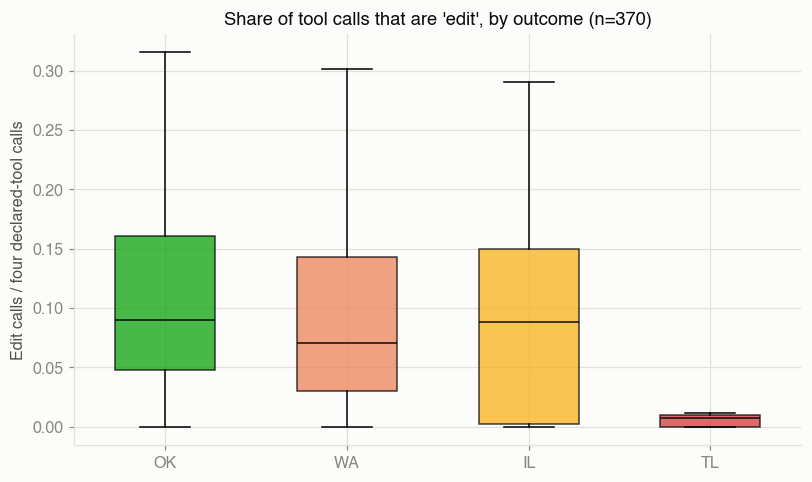

        count      mean       50%       std
status                                     
OK      218.0  0.109448  0.089899  0.082694
WA      121.0  0.097979  0.070175  0.095910
IL       26.0  0.100789  0.088529  0.096254
TL        5.0  0.005688  0.007101  0.005407


In [46]:
per_row_mix = tc.groupby(["row_id", "name"]).size().unstack(fill_value=0).reindex(columns=["read","bash","edit","write"], fill_value=0)
per_row_mix["total_calls"] = per_row_mix.sum(axis=1)
per_row_mix["edit_frac"] = per_row_mix["edit"] / per_row_mix["total_calls"].replace(0, np.nan)
row_df = row_df.merge(per_row_mix[["edit_frac"]], on="row_id", how="left", validate="one_to_one")
row_df["edit_frac"] = row_df["edit_frac"].fillna(0)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
data = [row_df.loc[row_df.status == s, "edit_frac"].values for s in atl.STATUS_ORDER]
bp = ax.boxplot(data, tick_labels=atl.STATUS_ORDER, patch_artist=True, showfliers=False, widths=0.55, medianprops={"color": atl.INK_PRIMARY})
for patch, s in zip(bp["boxes"], atl.STATUS_ORDER):
    patch.set_facecolor(atl.STATUS_COLORS[s])
    patch.set_alpha(0.75)
ax.set_ylabel("Edit calls / four declared-tool calls")
ax.set_title("Share of tool calls that are 'edit', by outcome (n=" + str(len(row_df)) + ")")
fig.tight_layout()
fig.savefig(OUT / "figures" / "10_edit_frac_by_status.png", dpi=150)
plt.show()
print(row_df.groupby("status")["edit_frac"].describe()[["count","mean","50%","std"]].reindex(atl.STATUS_ORDER))

Median edit-call fraction is about 0.007 for TL, compared with 0.090 (OK), 0.070 (WA), and 0.089 (IL). Only five TL traces are available. The association describes recorded actions and cannot establish that exploration caused failure or that more editing would help. OK and WA distributions overlap substantially.

### 10.3 First-order tool transitions

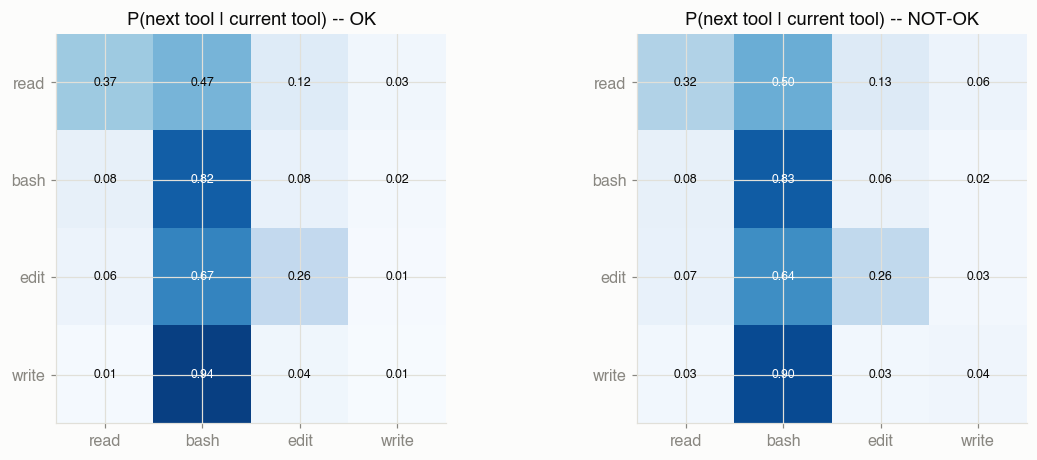

In [47]:
tc_sorted = tc.sort_values(["row_id", "call_id" if "call_id" in tc.columns else "row_id"])
tc_sorted = toolcall_df.merge(row_df[["row_id", "status"]], on="row_id", validate="many_to_one").sort_values(["row_id", "call_seq"])
tc_sorted["next_name"] = tc_sorted.groupby("row_id")["name"].shift(-1)
known = tc_sorted[tc_sorted.name.isin(["read","bash","edit","write"]) & tc_sorted.next_name.isin(["read","bash","edit","write"])]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, (grp, label) in zip(axes, [(known[known.status == "OK"], "OK"), (known[known.status != "OK"], "NOT-OK")]):
    trans = pd.crosstab(grp["name"], grp["next_name"], normalize="index").reindex(
        index=["read","bash","edit","write"], columns=["read","bash","edit","write"])
    im = ax.imshow(trans.values, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(4)); ax.set_xticklabels(trans.columns)
    ax.set_yticks(range(4)); ax.set_yticklabels(trans.index)
    ax.set_title(f"P(next tool | current tool) -- {label}")
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{trans.values[i,j]:.2f}", ha="center", va="center",
                     color="white" if trans.values[i,j] > 0.5 else atl.INK_PRIMARY, fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "figures" / "10_tool_transition_matrices.png", dpi=150)
plt.show()

**Weak/null result:** pooled first-order tool transitions look similar for OK and non-OK traces (`bash → bash` about 0.824 vs. 0.830, with a largest cell difference around 0.05). Long traces contribute more transitions, so this is an action-weighted description, not a per-task comparison. We did not pursue higher-order motifs because the coarse comparison offered limited separation and a more complex analysis was not justified by the available sample. This does not prove an absence of sequence-level signal.

## 11. Task, trial, job, and model hierarchy

**Question:** where does the observed design support comparisons? **Method:** aggregate counts at task and model level, with a worked task example. Trial IDs are unique, jobs map to one model label, and repeated task IDs carry identical user prompt text. There are 253 tasks and 370 attempts; 92 tasks repeat. Multi-model coverage is incomplete and uneven.

In [48]:
task_df = atl.build_task_level_table(row_df)
print(f"Distinct tasks: {len(task_df)}")
print(f"Tasks attempted by exactly 1 model: {(task_df.n_distinct_models == 1).sum()}")
print(f"Tasks attempted by 2+ models (multi-model coverage): {(task_df.n_distinct_models > 1).sum()}")
print()
print("Distribution of n_distinct_models per task:")
print(task_df["n_distinct_models"].value_counts().sort_index())

Distinct tasks: 253
Tasks attempted by exactly 1 model: 174
Tasks attempted by 2+ models (multi-model coverage): 79

Distribution of n_distinct_models per task:
n_distinct_models
1    174
2     68
3     10
4      1
Name: count, dtype: int64


Seventy-nine tasks (31.2%) were attempted by multiple models. This creates opportunities for pair-specific comparisons, but filtering to their union does not make each model's task set identical. The ranking in Section 18 is therefore a shared-task subset description, not a fully matched comparison. No task was attempted by all seven models.

In [49]:
multi = task_df[task_df.n_distinct_models > 1].copy()
multi["difficulty_class"] = np.select(
    [multi.mean_reward == 0, multi.mean_reward == 1],
    ["uniformly_failed", "uniformly_solved"],
    default="mixed_discriminating",
)
counts = multi["difficulty_class"].value_counts()
print(counts)
print(f"\n=> {counts.get('mixed_discriminating', 0)} of {len(multi)} multi-model tasks (",
      f"{counts.get('mixed_discriminating', 0)/len(multi):.0%}) have mixed observed outcomes;",
      f"{counts.get('uniformly_failed',0)} have only failures among observed attempts and",
      f"{counts.get('uniformly_solved',0)} have only successes among observed attempts.")

difficulty_class
mixed_discriminating    33
uniformly_solved        29
uniformly_failed        17
Name: count, dtype: int64

=> 33 of 79 multi-model tasks ( 42%) have mixed observed outcomes; 17 have only failures among observed attempts and 29 have only successes among observed attempts.


Forty-six of the 79 multi-model tasks have uniform observed binary outcomes; 33 have mixed outcomes. Uniformity in these few attempts does not establish intrinsic ease or difficulty. Mixed outcomes can reflect model or job differences or random variation. Grouped CV below uses **all** tasks, not just the mixed subset.

### 11.2 Worked example: the most-attempted task

In [50]:
top_task = task_df.sort_values("n_attempts", ascending=False).iloc[0]
tid = top_task["task_id"]
detail = row_df[row_df.task_id == tid][["row_id","model","job","status","reward","n_messages","n_proxy_requests","edit_frac"]]
detail = detail.sort_values("model")
print(f"Task: {tid}  ({int(top_task['n_attempts'])} attempts by {int(top_task['n_distinct_models'])} distinct models)")
print(detail.to_string(index=False))

Task: pybamm-team__pybamm-529  (5 attempts by 4 distinct models)
 row_id       model    job status  reward  n_messages  n_proxy_requests  edit_frac
    218 model-atlas run-10     WA       0         400               199   0.050505
    219  model-cyan run-01     OK       1         176                84   0.022222
    221  model-cyan run-07     OK       1         239               106   0.129771
    222 model-flint run-06     IL       0         201               100   0.130000
    220 model-orion run-05     TL       0         169                87   0.000000


`pybamm-team__pybamm-529` has five attempts from four models and two successes. This shows why task, model, and job context matter when interpreting a single result. It does not determine an optimal weighting scheme or an independent difficulty score.

### 11.3 Model aggregates with assignment caveats

In [51]:
model_df = atl.build_model_level_table(row_df)
model_df.to_parquet(OUT / "derived_tables" / "model_level.parquet")
task_df.to_parquet(OUT / "derived_tables" / "task_level.parquet")
model_df.set_index("model").reindex(atl.MODEL_ORDER)

,n_trials,n_distinct_tasks,mean_reward,median_n_proxy_requests,mean_n_messages,mean_n_tool_calls,mean_malformed_tool_calls
model,,,,,,,
model-atlas,40,40,0.400000,104.5,226.200000,111.800000,0.000000
model-cyan,60,42,0.783333,40.0,89.083333,45.316667,0.000000
model-delta,60,59,0.416667,55.0,331.250000,164.516667,0.050000
model-flint,60,55,0.350000,100.0,228.600000,113.766667,0.116667
model-garnet,30,28,0.533333,32.5,88.266667,44.800000,0.000000
model-orion,60,60,0.666667,49.0,104.150000,51.966667,0.133333
model-vega,60,60,0.883333,21.0,82.833333,40.116667,0.000000


We keep this table as a reference, but per Sections 8.4-8.5 we do **not** treat
`mean_reward` here as a clean capability ranking -- it is confounded with which (and
how many) tasks each model happened to be assigned, most severely for `model-flint`
and `model-garnet`, whose jobs used almost entirely disjoint task sets.

## 12. Descriptive failure taxonomy

**Question:** are failures dominated by very short traces? **Method:** retain recorded outcome labels and subdivide WA using the existing exploratory cutoff of 20 messages. This is a description of status and length, not a validated causal failure taxonomy. The threshold was selected after inspecting lengths; its sensitivity was not tested.

In [52]:
def classify_failure(r):
    if r["status"] == "OK":
        return "success"
    if r["status"] == "TL":
        return "TL (recorded status)"
    if r["status"] == "IL":
        return "IL (recorded status)"
    if r["status"] == "WA" and r["n_messages"] < 20:
        return "WA: short trace (<20 messages)"
    return "WA: trace >=20 messages"

row_df["failure_category"] = row_df.apply(classify_failure, axis=1)
cat_counts = row_df["failure_category"].value_counts()
print(cat_counts)

failure_category
success                           218
WA: trace >=20 messages           113
IL (recorded status)               26
WA: short trace (<20 messages)      8
TL (recorded status)                5
Name: count, dtype: int64


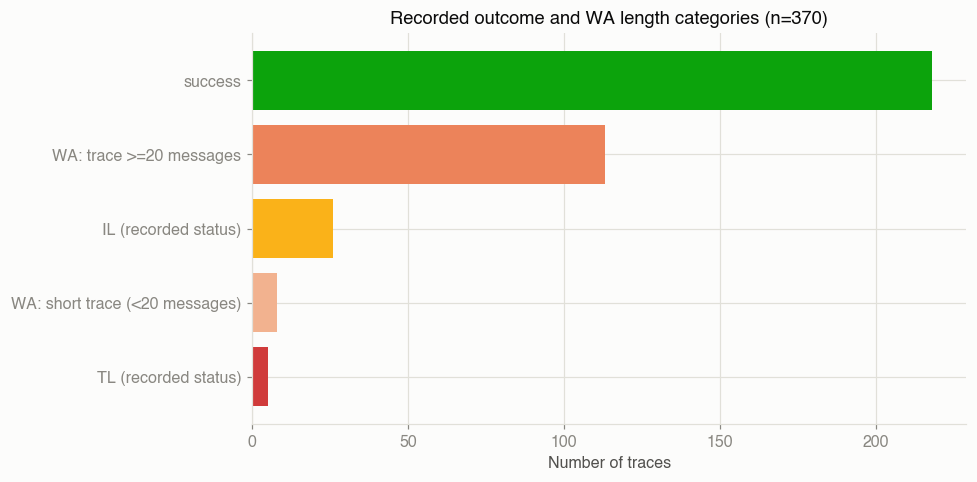

In [53]:
fig, ax = plt.subplots(figsize=(9, 4.5))
order = cat_counts.index[::-1]
cat_colors = {
    "success": atl.STATUS_COLORS["OK"],
    "WA: trace >=20 messages": atl.STATUS_COLORS["WA"],
    "WA: short trace (<20 messages)": "#f2b28f",
    "IL (recorded status)": atl.STATUS_COLORS["IL"],
    "TL (recorded status)": atl.STATUS_COLORS["TL"],
}
ax.barh(order, cat_counts.reindex(order), color=[cat_colors[c] for c in order])
ax.set_xlabel("Number of traces")
ax.set_title("Recorded outcome and WA length categories (n=370)")
fig.tight_layout()
fig.savefig(OUT / "figures" / "12_failure_taxonomy.png", dpi=150)
plt.show()

Eight of 121 WA traces have fewer than 20 messages (6.6%). Most WA traces therefore involve more recorded activity, but message count does not establish effort, patch quality, or premature abandonment. Inspecting short examples is necessary to avoid assigning a semantic cause from length alone.

In [54]:
degenerate = row_df[row_df["failure_category"].str.startswith("WA: short")]
print(degenerate[["row_id", "model", "task_id", "n_messages", "n_proxy_requests",
                   "final_msg_has_text", "self_reports_success"]].to_string(index=False))

 row_id       model                                              task_id  n_messages  n_proxy_requests  final_msg_has_text  self_reports_success
     70  model-vega                                    fatiando__verde-3          19                 9                True                  True
     82 model-delta                            geopandas__geopandas-2298           3                 5               False                 False
     95 model-delta googlecloudplatform__cloud-sql-python-connector-1108          15                14               False                 False
    144 model-delta                        litestar-org__polyfactory-479           7                10               False                 False
    173 model-delta                              parquery__icontract-297          19                19               False                 False
    234 model-delta                              pybamm-team__pybamm-669          11                15               False        

The original motivating example (row 70) has closing text, as does row 347; both claim tests pass. Thus short WA traces include confidently summarized attempts as well as traces without closing text. “Short WA” is the defensible category; “premature termination” is not established.

### 12.1 Unrecognized tool-call names and outcomes

In [55]:
row_df["has_malformed_call"] = row_df["n_malformed_tool_calls"] > 0
print(pd.crosstab(row_df["has_malformed_call"], row_df["status"], normalize="index").round(3))
print()
print(row_df.groupby("has_malformed_call")["reward"].agg(["mean","count"]))

status                 IL     OK     TL     WA
has_malformed_call                            
False               0.061  0.596  0.014  0.329
True                0.364  0.364  0.000  0.273

                        mean  count
has_malformed_call                 
False               0.596100    359
True                0.363636     11


The 13 traces with unrecognized call names have lower observed success. This small, confounded subgroup does not establish a causal parser failure or a reliable association in a wider population. The cause of the names remains unresolved.

## 13. Success patterns

**Question:** how little recorded activity can accompany success, and how do successful and failed attempts compare on tasks with mixed outcomes? **Method:** rank successful traces by request count, then pool attempts from the 33 mixed-outcome multi-model tasks. The pooled comparison retains unequal task and model weights; it does not estimate a within-task adjusted contrast.

### 13.1 Successful attempts with low request counts

In [56]:
ok = row_df[row_df.status == "OK"].sort_values("n_proxy_requests")
print("The 8 most efficient successful traces (fewest proxy requests):")
print(ok[["row_id","model","task_id","n_proxy_requests","n_messages","n_tool_calls","edit_frac"]].head(8).to_string(index=False))
print()
print("OK trace n_proxy_requests distribution:")
print(ok["n_proxy_requests"].describe())

The 8 most efficient successful traces (fewest proxy requests):
 row_id        model                                             task_id  n_proxy_requests  n_messages  n_tool_calls  edit_frac
    203   model-vega                       prometheus__client_python-547                 6          13             5   0.200000
    202   model-vega                      prometheus__client_python-1012                 6          13             5   0.200000
    290   model-cyan                                python__bedevere-641                 6          13             5   0.200000
    305   model-vega                        rigetticomputing__pyquil-264                 6          13             5   0.200000
     21   model-vega                                astropy__ccdproc-867                 7          15             6   0.166667
     90   model-cyan googlecloudplatform__cloud-sql-python-connector-476                 8          18             8   0.250000
    285  model-orion                    

The smallest successful examples use six proxy requests and 13 messages. This demonstrates a low recorded action count, not optimal efficiency or an absence of wasted work; elapsed time, exact token use, and task complexity are unavailable.

### 13.2 Pooled success/failure summaries on mixed-outcome tasks

In [57]:
mixed_ids = multi[multi.difficulty_class == "mixed_discriminating"]["task_id"]
matched = row_df[row_df.task_id.isin(mixed_ids)]
comp = matched.groupby("reward")[["n_messages","n_proxy_requests","edit_frac","frac_assistant_with_reasoning"]].median()
comp.index = ["failed (reward=0)", "succeeded (reward=1)"]
print(f"n attempts on mixed-outcome tasks: {len(matched)}  ({matched.task_id.nunique()} tasks)")
print(comp.round(3))
comp.to_csv(OUT / "derived_tables" / "pooled_mixed_task_medians.csv")

n attempts on mixed-outcome tasks: 83  (33 tasks)
                      n_messages  n_proxy_requests  edit_frac  frac_assistant_with_reasoning
failed (reward=0)          177.0              88.0      0.062                          0.750
succeeded (reward=1)       104.5              49.5      0.104                          0.747


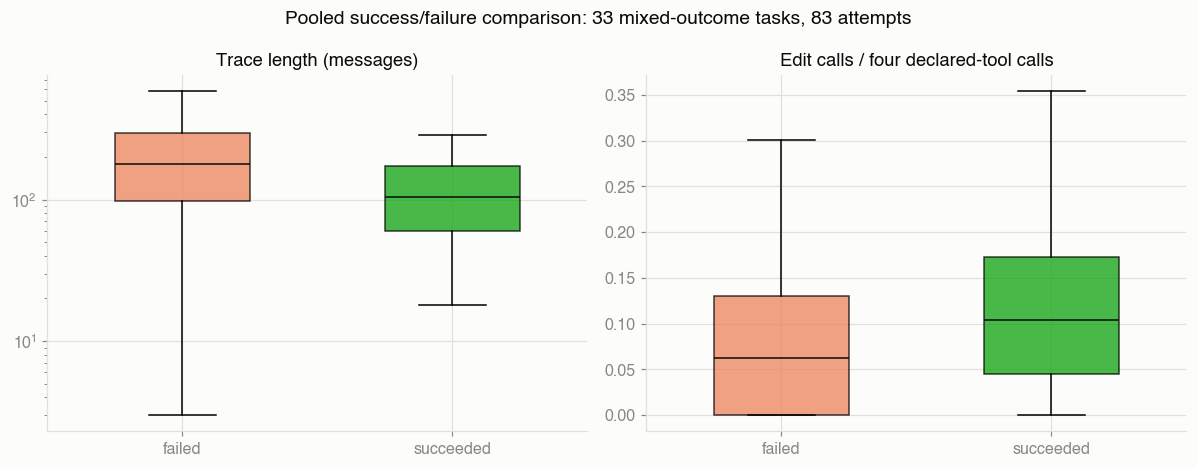

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, col, title in zip(axes, ["n_messages", "edit_frac"],
                            ["Trace length (messages)", "Edit calls / four declared-tool calls"]):
    data = [matched.loc[matched.reward == r, col].dropna().values for r in [0, 1]]
    bp = ax.boxplot(data, tick_labels=["failed", "succeeded"], patch_artist=True, showfliers=False, widths=0.5, medianprops={"color": atl.INK_PRIMARY})
    for patch, r in zip(bp["boxes"], [0, 1]):
        patch.set_facecolor(atl.STATUS_COLORS["WA"] if r == 0 else atl.STATUS_COLORS["OK"])
        patch.set_alpha(0.75)
    ax.set_title(title)
    if col == "n_messages":
        ax.set_yscale("log")
fig.suptitle(f"Pooled success/failure comparison: {len(mixed_ids)} mixed-outcome tasks, {len(matched)} attempts")
fig.tight_layout()
fig.savefig(OUT / "figures" / "13_pooled_success_failure.png", dpi=150)
plt.show()

Among 83 attempts on 33 mixed-outcome tasks, the pooled success median is 104.5 messages versus 177.0 for failures; median edit fractions are 0.104 and 0.062. Median reasoning-field coverage is about 0.75 in both groups.

These are medians of pooled attempts after task filtering. They neither balance task weights nor subtract within-task outcomes. Task/model/job composition may explain part of the difference, and selecting tasks by observed outcome variation is itself selective. No causal claim about length, editing, or reasoning follows.

## 14. Retrospective outcome classification

**Question:** what signal do completed-trace summaries and model/configuration fields provide about recorded success? **Method:** retain the existing logistic regression, depth-3 tree, and shallow forest. Five-fold `GroupKFold` groups by task ID; scaling is inside the logistic pipeline. These are pooled out-of-fold metrics on 370 attempts and 253 task groups.

The former “trace shape” feature set includes `dev_role` (a job-level configuration flag) and rate-limit events, so we name it **behaviour and configuration**. Model identity is compared separately and in combination. We retain the original feature sets rather than introduce new ablations. The historical audit's ablation is not promoted as a study result.

Length, final tool fractions, and rate-limit occurrence are available after completion. This is not an early-warning experiment. Task grouping prevents repeats of a task crossing folds, but jobs remain represented in training: these results do not establish transfer to new jobs, configurations, or semantically related unseen task families. Compare AUC with a constant-score AUC of 0.5 and accuracy with majority accuracy of 0.589.

In [59]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, accuracy_score, brier_score_loss

df_model = row_df.copy()
df_model["log_n_messages"] = np.log1p(df_model["n_messages"])
df_model["dev_role"] = (df_model["system_role_convention"] == "developer").astype(int)
df_model["rate_limited"] = df_model["has_rate_limit_events"].astype(int)

feature_cols_numeric = ["log_n_messages", "edit_frac", "frac_assistant_with_reasoning",
                          "n_malformed_tool_calls", "dev_role", "rate_limited"]
X_num = df_model[feature_cols_numeric].fillna(0).values
model_dummies = pd.get_dummies(df_model["model"], prefix="model")
X_model_id = model_dummies.values
X_full = np.hstack([X_num, X_model_id])
feat_names = feature_cols_numeric + list(model_dummies.columns)

y = df_model["reward"].values
groups = df_model["task_id"].values
gkf = GroupKFold(n_splits=5)

print(f"n rows: {len(df_model)}, n task groups: {len(np.unique(groups))}, n features: {X_full.shape[1]}")
print(f"Majority-class baseline accuracy: {max(y.mean(), 1-y.mean()):.3f}")

n rows: 370, n task groups: 253, n features: 13
Majority-class baseline accuracy: 0.589


In [60]:
pipe = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=2000, C=0.5))])

results = {}
for label, X in [("behaviour and configuration", X_num),
                  ("model identity only", X_model_id),
                  ("behaviour, configuration and identity", X_full)]:
    probs = cross_val_predict(pipe, X, y, cv=gkf, groups=groups, method="predict_proba")[:, 1]
    preds = (probs >= 0.5).astype(int)
    results[label] = {
        "AUC": roc_auc_score(y, probs),
        "Accuracy": accuracy_score(y, preds),
        "Brier": brier_score_loss(y, probs),
    }
res_df = pd.DataFrame(results).T
print("Logistic regression, 5-fold GroupKFold-by-task_id cross-validated performance:")
print(res_df)
res_df.to_csv(OUT / "derived_tables" / "logistic_cv_scores.csv")

Logistic regression, 5-fold GroupKFold-by-task_id cross-validated performance:
                                            AUC  Accuracy     Brier
behaviour and configuration            0.699179  0.635135  0.217593
model identity only                    0.698877  0.672973  0.211049
behaviour, configuration and identity  0.703766  0.659459  0.212740


The logistic models have AUCs of about 0.699 (behaviour/configuration), 0.699 (identity), and 0.704 (combined). Identical rounded AUCs do not demonstrate equivalence; accuracy and Brier scores differ. The combined accuracy is about 0.66 versus the descriptive majority-class accuracy of 0.589. Constant-score AUC is 0.5. No confidence interval for score differences was calculated.

The observed scores show modest retrospective discrimination for these specifications. They cannot decompose independent causal contributions of behaviour, identity, and configuration.

### 14.1 Full-data coefficients for description

Logistic regression coefficients (standardized features; full-data fit for interpretation only):
                      feature  coefficient
                     dev_role    -0.754961
            model_model-flint    -0.335120
frac_assistant_with_reasoning    -0.249484
               log_n_messages    -0.217837
           model_model-garnet    -0.148967
            model_model-delta    -0.103294
            model_model-orion    -0.097580
                    edit_frac    -0.012739
       n_malformed_tool_calls    -0.003845
                 rate_limited     0.025865
            model_model-atlas     0.034601
             model_model-vega     0.213434
             model_model-cyan     0.403727


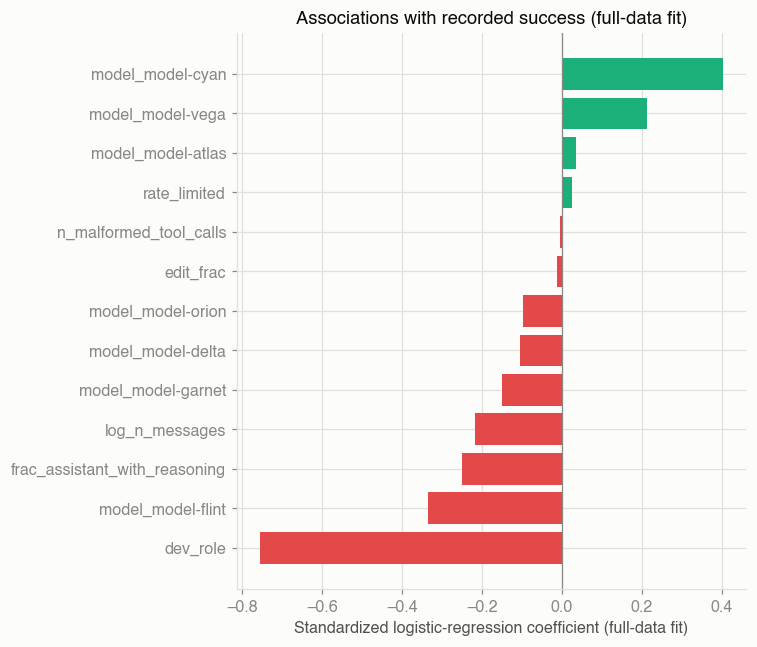

In [61]:
pipe.fit(X_full, y)
coefs = pipe.named_steps["clf"].coef_[0]
coef_df = pd.DataFrame({"feature": feat_names, "coefficient": coefs}).sort_values("coefficient")
print("Logistic regression coefficients (standardized features; full-data fit for interpretation only):")
print(coef_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 6))
colors = [atl.CATEGORICAL_PALETTE[7] if c < 0 else atl.CATEGORICAL_PALETTE[4] for c in coef_df["coefficient"]]
ax.barh(coef_df["feature"], coef_df["coefficient"], color=colors)
ax.axvline(0, color=atl.INK_MUTED, linewidth=0.8)
ax.set_xlabel("Standardized logistic-regression coefficient (full-data fit)")
ax.set_title("Associations with recorded success (full-data fit)")
fig.tight_layout()
fig.savefig(OUT / "figures" / "14_logistic_coefficients.png", dpi=150)
plt.show()

The full-data logistic fit gives `dev_role` a large negative coefficient. This reuses the same observations as the cyan comparison and is **not independent corroboration**. Job, date, role convention, model, and task assignment remain entangled; regularized coefficients are conditional associations, not interventions. Trace length and reasoning-field coefficients also cannot establish effects of more work or more reasoning.

### 14.2 Existing tree and forest comparisons

In [62]:
tree_probs = cross_val_predict(
    DecisionTreeClassifier(max_depth=3, min_samples_leaf=15, random_state=RANDOM_SEED),
    X_full, y, cv=gkf, groups=groups, method="predict_proba")[:, 1]
rf = RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=8, random_state=RANDOM_SEED)
rf_probs = cross_val_predict(rf, X_full, y, cv=gkf, groups=groups, method="predict_proba")[:, 1]

print(f"Decision tree (depth<=3), grouped CV AUC: {roc_auc_score(y, tree_probs):.3f}")
print(f"Random forest (300 trees, depth<=5), grouped CV AUC: {roc_auc_score(y, rf_probs):.3f}")
print(f"(for comparison) Logistic regression, grouped CV AUC: {res_df.loc['behaviour, configuration and identity', 'AUC']:.3f}")
pd.DataFrame({"model": ["tree", "forest"], "AUC": [roc_auc_score(y, tree_probs), roc_auc_score(y, rf_probs)]}).to_csv(OUT / "derived_tables" / "nonlinear_cv_scores.csv", index=False)

Decision tree (depth<=3), grouped CV AUC: 0.709
Random forest (300 trees, depth<=5), grouped CV AUC: 0.762
(for comparison) Logistic regression, grouped CV AUC: 0.704


The depth-3 tree reaches AUC 0.709 and the shallow forest 0.762 under the same task-grouped folds, compared with logistic AUC 0.704. These are scores of the models tried, not an estimated predictive ceiling. No uncertainty analysis establishes which model generalizes better. We stop at the existing models; more flexible modelling and early-prefix evaluation are future work.

In [63]:
print(f"{len(y)} attempts; {len(set(groups))} task groups; {X_full.shape[1]} full-model inputs.")
print(f"Outcomes: {int(y.sum())} successes; {int((1-y).sum())} failures. Coefficients are descriptive, without inferential p-values.")

370 attempts; 253 task groups; 13 full-model inputs.
Outcomes: 218 successes; 152 failures. Coefficients are descriptive, without inferential p-values.


## 15. Task-text signals and duplicate screening

**Question:** does prompt length associate with success, and does a lexical screen flag similar task prompts? **Method:** point-biserial correlation on attempts, TF-IDF cosine similarity over 253 unique prompts, and the existing KMeans comparison with repository families. TF-IDF is a bounded exploratory screen; semantic duplication and train/test contamination cannot be excluded by it. Sentence embeddings were considered but not implemented because there was no sufficiently specific additional question within scope.

### 15.1 Prompt length and outcome

In [64]:
from scipy import stats as sstats2

r, p = sstats2.pointbiserialr(row_df["reward"], row_df["user_prompt_len"])
print(f"Point-biserial correlation(reward, user_prompt_len): r={r:.3f}, p={p:.3f}")
print()
print(row_df.groupby("status")["user_prompt_len"].median().reindex(atl.STATUS_ORDER))
prompt_length_r, prompt_length_p = float(r), float(p)

Point-biserial correlation(reward, user_prompt_len): r=0.023, p=0.658

status
OK    3494.5
WA    3793.0
IL    3310.5
TL    4484.0
Name: user_prompt_len, dtype: float64


Prompt length has little observed linear association with binary success (r=0.023, nominal p≈0.66). The correlation is attempt-weighted, and its nominal p-value does not account for repeated tasks/jobs. This is a useful weak result for this simple feature, not proof that task wording or complexity has no effect.

### 15.2 Lexical duplicate-candidate screen

In [65]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

uniq_tasks = row_df.drop_duplicates("task_id")[["task_id", "user_prompt"]].reset_index(drop=True)
vec = TfidfVectorizer(max_df=0.8, min_df=2, stop_words="english")
X_tfidf = vec.fit_transform(uniq_tasks["user_prompt"])
sim = cosine_similarity(X_tfidf)
np.fill_diagonal(sim, 0)

flat_idx = np.dstack(np.unravel_index(np.argsort(-sim, axis=None), sim.shape))[0]
seen, top_pairs = set(), []
for i, j in flat_idx:
    if i < j and (i, j) not in seen:
        seen.add((i, j))
        top_pairs.append((uniq_tasks.task_id[i], uniq_tasks.task_id[j], sim[i, j]))
    if len(top_pairs) >= 8:
        break
pd.DataFrame(top_pairs, columns=["task_id_a", "task_id_b", "cosine_similarity"])
pd.DataFrame(top_pairs, columns=["task_id_a", "task_id_b", "cosine_similarity"]).to_csv(OUT / "derived_tables" / "lexical_similarity_candidates.csv", index=False)
print(pd.DataFrame(top_pairs, columns=["task_id_a", "task_id_b", "cosine_similarity"]).to_string(index=False))

                                          task_id_a                                           task_id_b  cosine_similarity
                                  conda__conda-1807                                   conda__conda-1808           0.883091
                           pybamm-team__pybamm-2862                            pybamm-team__pybamm-2961           0.808581
                      litestar-org__polyfactory-472                       litestar-org__polyfactory-587           0.765713
                      litestar-org__polyfactory-472                       litestar-org__polyfactory-499           0.764025
                            pybamm-team__pybamm-661                             pybamm-team__pybamm-962           0.762646
googlecloudplatform__cloud-sql-python-connector-476 googlecloudplatform__cloud-sql-python-connector-475           0.747593
                      litestar-org__polyfactory-479                       litestar-org__polyfactory-499           0.744596
                

The maximum cross-task TF-IDF cosine similarity is **0.883091**, for `conda__conda-1807` and `conda__conda-1808`. Distinct issue IDs do not prove independent content. This particular screen found no stronger candidate; it does not rule out near duplicates, shared solutions, or other leakage. Task grouping in CV does not address all such relationships.

### 15.3 Text clusters versus repository families

In [66]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

k = uniq_tasks["task_id"].map(lambda t: row_df.loc[row_df.task_id == t, "task_family"].iloc[0]).nunique()
km = KMeans(n_clusters=min(k, 30), random_state=RANDOM_SEED, n_init=10)
cluster_labels = km.fit_predict(X_tfidf)
family_labels = uniq_tasks["task_id"].map(lambda t: row_df.loc[row_df.task_id == t, "task_family"].iloc[0])

ari = adjusted_rand_score(family_labels, cluster_labels)
print(f"Adjusted Rand Index between TF-IDF KMeans clusters (k={min(k,30)}) and repo-derived task_family: {ari:.3f}")
print("(1.0 = identical partitions; 0.0 = chance-adjusted agreement)")

Adjusted Rand Index between TF-IDF KMeans clusters (k=30) and repo-derived task_family: 0.387
(1.0 = identical partitions; 0.0 = chance-adjusted agreement)


Thirty KMeans clusters compared with 77 repository families yield ARI **0.387**. This is partial agreement, not near-exact recovery or validation of a difficulty measure. Repository names occur in the prompts, so lexical overlap is expected. The coarse clustering adds limited interpretive value beyond directly extracted repository labels; we do not pursue topic modelling.

## 16. Sequence and Process Analysis

**Question:** treating each trace as a *process* rather than a static row, what does
its role/action sequence look like, and does that sequence structure differ by outcome?
**Why:** Section 10.3 already tested tool-transition structure and found it weak;
this section completes the picture with the role-level process view and documents why
we did not push further into higher-order sequence models. **Method:** transition
matrices and a labelled process diagram built directly from `msg_df`.

In [67]:
msg_sorted = msg_df.sort_values(["row_id", "msg_index"])
msg_sorted["next_role"] = msg_sorted.groupby("row_id")["role"].shift(-1)
role_trans = pd.crosstab(msg_sorted["role"], msg_sorted["next_role"])
print("Role-transition COUNT matrix (rows = current role, cols = next role):")
print(role_trans)

Role-transition COUNT matrix (rows = current role, cols = next role):
next_role  assistant   tool  user
role                             
assistant         45  29996     0
developer          0      0   153
system             0      0   217
tool           29988    712     0
user             370      0     0


The transition table records 370 user→assistant transitions and 370 setup→user transitions. There are 712 tool→tool transitions, compatible with multiple calls in an assistant turn; the ID audit cautions against assuming every adjacent result is correctly paired. Forty-five assistant→assistant transitions remain unexplained. This table describes ordering and cannot identify harness mechanisms.

### 16.1 Process overview

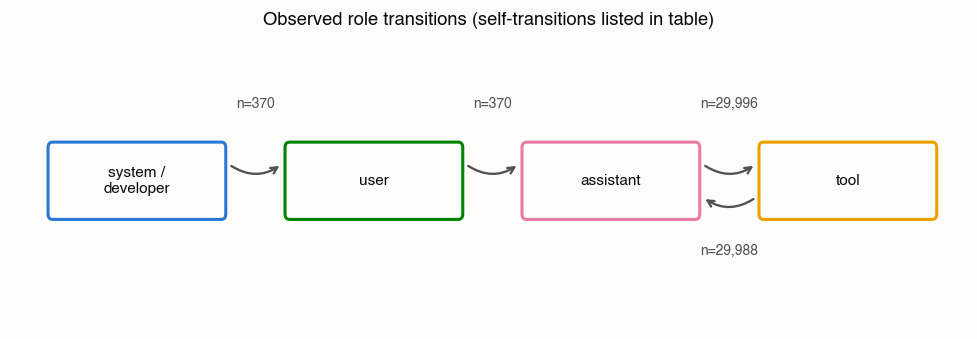

In [68]:
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(9, 3.2))
node_pos = {"system/developer": (0, 0), "user": (1.6, 0), "assistant": (3.2, 0), "tool": (4.8, 0)}
for index, (name, (x, y)) in enumerate(node_pos.items()):
    ax.add_patch(FancyBboxPatch((x-0.57, y-0.18), 1.14, 0.36,
        boxstyle="round,pad=0.03", facecolor=atl.SURFACE,
        edgecolor=atl.CATEGORICAL_PALETTE[index], linewidth=2, zorder=3))
    label = "system /\ndeveloper" if name == "system/developer" else name
    ax.text(x, y, label, ha="center", va="center", fontsize=10, color=atl.INK_PRIMARY, zorder=4)

edges = [("system/developer", "user", int(role_trans.loc[["system", "developer"], "user"].sum())),
         ("user", "assistant", int(role_trans.loc["user", "assistant"])),
         ("assistant", "tool", int(role_trans.loc["assistant", "tool"])),
         ("tool", "assistant", int(role_trans.loc["tool", "assistant"]))]
for a, b, count in edges:
    xa, ya = node_pos[a]; xb, yb = node_pos[b]
    reverse = a == "tool"
    start = (xa + (-0.62 if reverse else 0.62), -0.09 if reverse else 0.09)
    end = (xb + (0.62 if reverse else -0.62), -0.09 if reverse else 0.09)
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(
        arrowstyle="->", lw=1.5, color=atl.INK_SECONDARY,
        connectionstyle="arc3,rad=-0.35" if reverse else "arc3,rad=0.35"))
    ax.text((xa+xb)/2, -0.4 if reverse else 0.4, f"n={count:,}",
            fontsize=9, ha="center", color=atl.INK_SECONDARY)
ax.set_xlim(-0.85, 5.6); ax.set_ylim(-0.8, 0.8)
ax.axis("off")
ax.set_title("Observed role transitions (self-transitions listed in table)")
fig.tight_layout()
fig.savefig(OUT / "figures" / "16_role_process_diagram.png", dpi=150)
plt.show()

Most recorded transitions follow a setup message, one user task, and an assistant/tool loop, with occasional assistant-to-assistant transitions. This common topology limits role-level differentiation; it does not imply all sequences are identical or explain exceptional transitions. Tool identities and loop lengths offer finer descriptions. Higher-order sequence modelling remains unperformed.

## 17. Task/model coverage graph

**Question:** does a graph clarify coverage beyond the tables? **Method:** an undirected bipartite graph on multi-model tasks; repeated attempts aggregate into edge weights and reward sums. A task node's colour averages model-specific edge success fractions, equally weighting models rather than attempts. The graph visualizes observed coverage and outcomes, not latent ability or causal task difficulty.

In [69]:
import networkx as nx

multi_tasks = task_df[task_df.n_distinct_models > 1]["task_id"]
sub = row_df[row_df.task_id.isin(multi_tasks)]

G = nx.Graph()
for _, r in sub.iterrows():
    tnode, mnode = f"T::{r.task_id}", f"M::{r.model}"
    G.add_node(tnode, kind="task")
    G.add_node(mnode, kind="model")
    if G.has_edge(tnode, mnode):
        G[tnode][mnode]["weight"] += 1
        G[tnode][mnode]["reward_sum"] += r.reward
    else:
        G.add_edge(tnode, mnode, weight=1, reward_sum=r.reward)

print(f"Bipartite graph: {G.number_of_nodes()} nodes ({sum(1 for n,d in G.nodes(data=True) if d['kind']=='task')} tasks, "
      f"{sum(1 for n,d in G.nodes(data=True) if d['kind']=='model')} models), {G.number_of_edges()} edges")
model_degree = {n: G.degree(n) for n in G.nodes if G.nodes[n]["kind"] == "model"}
print("\nModel node degree (= number of distinct multi-model tasks this model participated in):")
for m, d in sorted(model_degree.items(), key=lambda x: -x[1]):
    print(f"  {m:20s} {d}")

Bipartite graph: 86 nodes (79 tasks, 7 models), 170 edges

Model node degree (= number of distinct multi-model tasks this model participated in):
  M::model-delta       34
  M::model-flint       26
  M::model-orion       25
  M::model-cyan        24
  M::model-atlas       23
  M::model-vega        22
  M::model-garnet      16


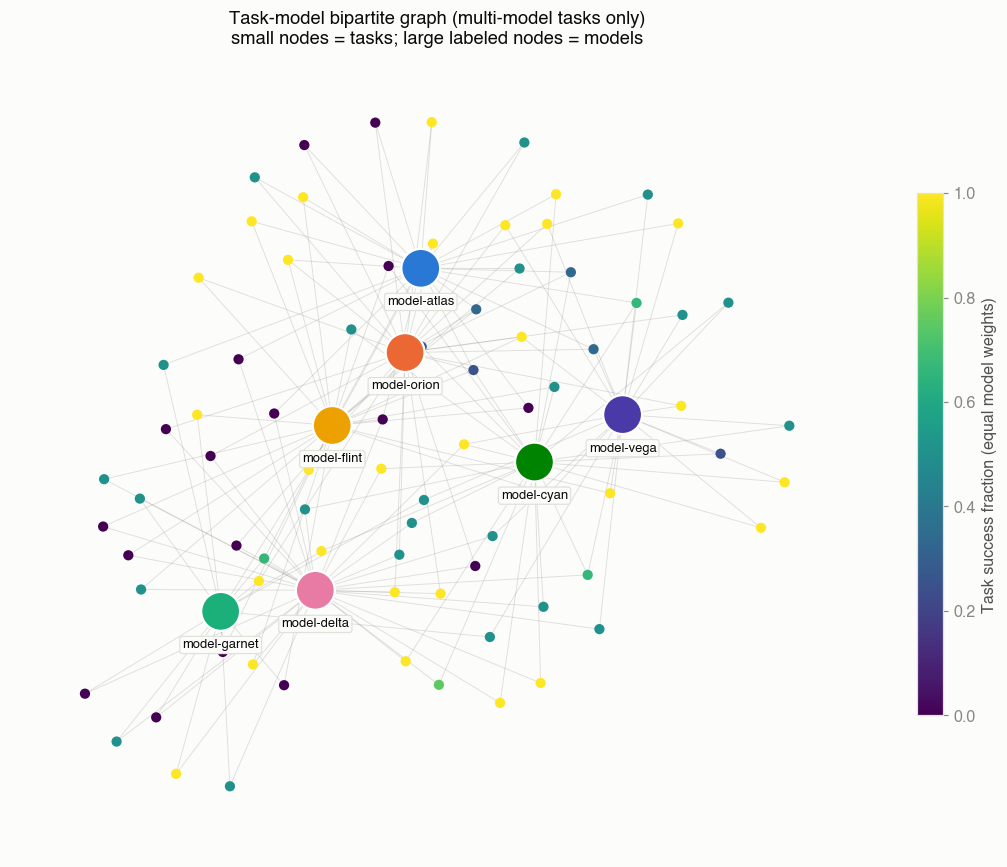

In [70]:
fig, ax = plt.subplots(figsize=(10, 8))
pos = nx.spring_layout(G, seed=RANDOM_SEED, k=0.35)
task_nodes = [n for n, d in G.nodes(data=True) if d["kind"] == "task"]
model_nodes = [n for n, d in G.nodes(data=True) if d["kind"] == "model"]

task_reward = {n: np.mean([G[n][nb]["reward_sum"] / G[n][nb]["weight"] for nb in G[n]]) for n in task_nodes}
node_colors = [plt.cm.viridis(task_reward[n]) for n in task_nodes]

nx.draw_networkx_edges(G, pos, alpha=0.25, width=0.6, ax=ax, edge_color=atl.INK_MUTED)
nx.draw_networkx_nodes(G, pos, nodelist=task_nodes, node_size=45, node_color=node_colors, ax=ax, linewidths=0)
nx.draw_networkx_nodes(G, pos, nodelist=model_nodes, node_size=650,
                        node_color=[atl.MODEL_COLORS[m.replace("M::", "")] for m in model_nodes], ax=ax,
                        edgecolors="white", linewidths=1.5)
# Labels are placed just BELOW each model node (not centered inside it) -- an 11-character
# name like "model-atlas" does not fit inside a node circle at a legible font size.
label_pos = {n: (x, y - 0.08) for n, (x, y) in pos.items() if n in model_nodes}
for n, (x, y) in label_pos.items():
    ax.text(x, y, n.replace("M::", ""), fontsize=8.5, ha="center", va="top", color=atl.INK_PRIMARY,
            weight="bold", bbox=dict(boxstyle="round,pad=0.2", fc=atl.SURFACE, ec=atl.GRID_COLOR, lw=0.8))
ax.set_title("Task-model bipartite graph (multi-model tasks only)\nsmall nodes = tasks; large labeled nodes = models")
fig.colorbar(mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(0, 1), cmap="viridis"), ax=ax, shrink=0.65, label="Task success fraction (equal model weights)")
ax.axis("off")
fig.tight_layout()
fig.savefig(OUT / "figures" / "17_task_model_bipartite.png", dpi=150)
plt.show()

The graph makes incomplete, uneven coverage visible. Its layout and colours do not provide an additional statistical test or adjusted model comparison; the underlying information is already in the relational tables. We retain it as an explanatory visualization and do not infer clusters or capabilities from spatial proximity.

## 18. Alternative summaries and their limits

**Question:** how do existing descriptive summaries change under task filtering and different aggregation choices? **Method:** compare raw and multi-model-subset rankings, display separately normalized status tool mixes without TL, and compare means with medians. These limited checks do not constitute a comprehensive robustness or uncertainty study.

### 18.1 Raw rates and the shared-task subset

In [71]:
full_rank = row_df.groupby("model")["reward"].mean().sort_values(ascending=False)
matched_rank = row_df[row_df.task_id.isin(multi_tasks)].groupby("model")["reward"].mean().sort_values(ascending=False)
n_matched = row_df[row_df.task_id.isin(multi_tasks)].groupby("model").size()

cmp_df = pd.DataFrame({
    "all_tasks_success_rate": full_rank,
    "shared_subset_success_rate": matched_rank,
    "n_shared_subset_attempts": n_matched,
}).reindex(atl.MODEL_ORDER)
print(cmp_df.round(3))

from scipy.stats import spearmanr
rho, p = spearmanr(full_rank.reindex(atl.MODEL_ORDER), matched_rank.reindex(atl.MODEL_ORDER))
print(f"\nSpearman rank correlation between the two rankings: rho={rho:.3f}, p={p:.3f}")
cmp_df["n_distinct_subset_tasks"] = row_df[row_df.task_id.isin(multi_tasks)].groupby("model").task_id.nunique()
cmp_df.to_csv(OUT / "derived_tables" / "raw_and_shared_subset_rates.csv")

              all_tasks_success_rate  shared_subset_success_rate  n_shared_subset_attempts
model                                                                                     
model-atlas                    0.400                       0.348                        23
model-cyan                     0.783                       0.844                        32
model-delta                    0.417                       0.371                        35
model-flint                    0.350                       0.464                        28
model-garnet                   0.533                       0.444                        18
model-orion                    0.667                       0.640                        25
model-vega                     0.883                       0.909                        22

Spearman rank correlation between the two rankings: rho=0.786, p=0.036


Vega and cyan occupy the top two positions under both summaries. The raw bottom two are **flint (35%) and atlas (40%)**; the shared-task subset bottom two are atlas and delta. The rank correlation is about 0.79.

The subset contains different distinct task counts for atlas, cyan, delta, flint, garnet, orion, and vega (23, 24, 34, 26, 16, 25, and 22). No task includes all seven models, and repeats give some cells extra weight. Neither ranking is a fully matched or adjusted capability estimate. Pairwise common-task studies and task-level uncertainty belong to future work.

### 18.2 Displaying status-normalized tool mixes without TL

In [72]:
mix_excl_tl = tc[tc.status != "TL"].groupby(["status", "name"]).size().unstack(fill_value=0)
mix_excl_tl = mix_excl_tl.reindex(index=["OK","WA","IL"])[["read","bash","edit","write"]]
mix_excl_tl = mix_excl_tl.div(mix_excl_tl.sum(axis=1), axis=0)
print("Tool-mix shares, TL excluded:")
print(mix_excl_tl.round(3))
print("Separately normalized groups are unchanged by construction.")

Tool-mix shares, TL excluded:
name     read   bash   edit  write
status                            
OK      0.110  0.774  0.096  0.019
WA      0.133  0.735  0.102  0.029
IL      0.093  0.764  0.112  0.031
Separately normalized groups are unchanged by construction.


The remaining status shares are unchanged **by construction**, because each status group is normalized separately. This is a display identity, not independent robustness evidence. The TL pattern is descriptive and based on five traces; exclusion does not validate its interpretation.

### 18.3 Means and medians for heavy-tailed counts

In [73]:
for col in ["n_proxy_requests", "n_messages"]:
    cmp = row_df.groupby("status")[col].agg(["mean", "median"]).reindex(atl.STATUS_ORDER)
    print(f"--- {col} ---")
    print(cmp.round(1))
    print()

--- n_proxy_requests ---
         mean  median
status               
OK       69.0    41.0
WA       73.1    66.0
IL      152.9   187.5
TL      581.2   100.0

--- n_messages ---
          mean  median
status                
OK       139.3    85.0
WA       146.0   133.0
IL       307.8   375.0
TL      1161.8   199.0



TL has a large mean–median gap driven by extreme traces; IL counts cluster high, and OK/WA summaries overlap more closely. Comparing both summaries shows the tail's influence. It does not verify IL/TL semantics or generalization. No terminal-tool exclusion, cutoff sensitivity, bootstrap, or new validation protocol is claimed.

## 19. Representative cases

The following selected traces illustrate earlier quantitative questions: low-count success, short WA, long TL, IL at 100 requests, a cyan job pair, an unrecognized name, and the five-attempt task. These purposive examples are not a representative sample or independent evidence. The publication view reports indices and scalar summaries without verbatim message or argument text. Readers can inspect the identified rows in the upstream dataset.

In [74]:
def show_case(row_id, label, section_ref):
    record = row_df.set_index("row_id").loc[row_id]
    print(f"### {label} (refers to {section_ref})")
    for field in ["model", "job", "task_id", "status", "n_messages", "n_proxy_requests",
                  "final_msg_has_text", "self_reports_success"]:
        print(f"{field}: {record[field]}")
    print("Verbatim transcript text omitted; inspect this row in the upstream dataset.")
    print()

show_case(203, "13.1 Low-count success", "Section 13.1")

### 13.1 Low-count success (refers to Section 13.1)
model: model-vega
job: run-15
task_id: prometheus__client_python-547
status: OK
n_messages: 13
n_proxy_requests: 6
final_msg_has_text: True
self_reports_success: True
Verbatim transcript text omitted; inspect this row in the upstream dataset.



**19.1 Low-count success:** row 203 records six requests and 13 messages. The recorded metadata illustrates a successful short trace; it does not establish optimality or independently verify the agent's claimed tests.

In [75]:
show_case(82, "Short WA without closing text", "Section 12")

### Short WA without closing text (refers to Section 12)
model: model-delta
job: run-03
task_id: geopandas__geopandas-2298
status: WA
n_messages: 3
n_proxy_requests: 5
final_msg_has_text: False
self_reports_success: False
Verbatim transcript text omitted; inspect this row in the upstream dataset.



**19.2 Short WA:** row 82 has three messages and no closing text. It illustrates one short-failure endpoint, whereas rows 70 and 347 show why this cannot characterize all short WA attempts.

In [76]:
show_case(263, "Long TL trace", "Sections 8.1, 10.2")

### Long TL trace (refers to Sections 8.1, 10.2)
model: model-delta
job: run-12
task_id: pygfx__pygfx-121
status: TL
n_messages: 3573
n_proxy_requests: 1786
final_msg_has_text: False
self_reports_success: False
Verbatim transcript text omitted; inspect this row in the upstream dataset.



**19.3 Long TL:** row 263 has 3,573 messages, 1,786 requests, and no final text. This illustrates the heavy tail. A wall-clock explanation is compatible with it but unverified without timing and grader logs.

In [77]:
show_case(6, "IL at 100 requests", "Section 8.1")

### IL at 100 requests (refers to Section 8.1)
model: model-flint
job: run-06
task_id: aeon-toolkit__aeon-2565
status: IL
n_messages: 201
n_proxy_requests: 100
final_msg_has_text: False
self_reports_success: False
Verbatim transcript text omitted; inspect this row in the upstream dataset.



**19.4 IL at 100 requests:** row 6 has 201 messages and no closing text, consistent with the proposed request-budget interpretation. The actual stop rule is unavailable.

### 19.5 Cyan job disagreement on one common task

In [78]:
show_case(2, "cyan / run-01 / aeon-1767 -- succeeded", "Section 8.6")
show_case(1, "cyan / run-07 / aeon-1767 -- failed, SAME task", "Section 8.6")

### cyan / run-01 / aeon-1767 -- succeeded (refers to Section 8.6)
model: model-cyan
job: run-01
task_id: aeon-toolkit__aeon-1767
status: OK
n_messages: 101
n_proxy_requests: 46
final_msg_has_text: True
self_reports_success: False
Verbatim transcript text omitted; inspect this row in the upstream dataset.

### cyan / run-07 / aeon-1767 -- failed, SAME task (refers to Section 8.6)
model: model-cyan
job: run-07
task_id: aeon-toolkit__aeon-1767
status: WA
n_messages: 67
n_proxy_requests: 32
final_msg_has_text: True
self_reports_success: False
Verbatim transcript text omitted; inspect this row in the upstream dataset.



Both selected cyan attempts contain success-claiming closing language despite different recorded outcomes. This motivated the full-snapshot regex screen in Section 9, whose weak result is the appropriate basis for population interpretation. The pair alone cannot establish language reliability. Message text is omitted from this publication view.

### 19.6 Unrecognized call name

In [79]:
case_calls = toolcall_df[toolcall_df.row_id.eq(42)]
case_bad = case_calls[~case_calls.matched_known_tool]
print(row_df.loc[row_df.row_id.eq(42), ["row_id", "model", "task_id", "status"]].to_string(index=False))
print("Unrecognized calls:", len(case_bad))
print("Calls with leading whitespace:", int(case_bad.name.fillna("").str.match(r"^\s").sum()))
print("Recorded names and arguments are omitted from the publication view.")

 row_id       model         task_id status
     42 model-orion ctfd__ctfd-2767     OK
Unrecognized calls: 2
Calls with leading whitespace: 2
Recorded names and arguments are omitted from the publication view.


A stored call name contains leading whitespace before a declared tool name. The trace is recorded OK. This demonstrates a name mismatch in the exported data, without establishing who introduced it or whether it affected execution. Raw names and arguments are omitted.

### 19.7 A multi-model task with mixed outcomes

In [80]:
print(detail.to_string(index=False))
print("\n(pybamm-team__pybamm-529: 4 different models, 5 attempts, 40% success -- see Section 11.2)")

 row_id       model    job status  reward  n_messages  n_proxy_requests  edit_frac
    218 model-atlas run-10     WA       0         400               199   0.050505
    219  model-cyan run-01     OK       1         176                84   0.022222
    221  model-cyan run-07     OK       1         239               106   0.129771
    222 model-flint run-06     IL       0         201               100   0.130000
    220 model-orion run-05     TL       0         169                87   0.000000

(pybamm-team__pybamm-529: 4 different models, 5 attempts, 40% success -- see Section 11.2)


In [81]:
case_study_rows = [203, 82, 263, 6, 2, 1, 42] + detail["row_id"].tolist()
case_study_export = row_df[row_df.row_id.isin(case_study_rows)][
    ["row_id","model","job","task_id","status","reward","n_messages","n_proxy_requests","edit_frac"]
].drop_duplicates("row_id")
case_study_export.to_csv(OUT / "case_studies" / "selected_case_studies.csv", index=False)
print(f"Saved {len(case_study_export)} case-study rows to analysis_outputs/case_studies/selected_case_studies.csv")

Saved 12 case-study rows to analysis_outputs/case_studies/selected_case_studies.csv


## 20. Integrated findings

The structural audit supports reliable scalar/count aggregation while exposing limits on action/result reconstruction. Reward is exactly the OK indicator; 90.7% of assistant messages omit content; the identifier audit separately identifies orphan results, unanswered calls, and a reused ID. Passing count reconciliation is not proof of complete transcripts.

Model rates and repository-family outcome differences describe an uneven observational design. Shared-task filtering retains unequal assignment. The clearest task-controlled contrast is cyan's 17/18 versus 10/18 successes across two jobs, with seven one-directional disagreements; role convention, date, and unobserved job conditions prevent causal attribution. The 8/26 repeated-group disagreements largely reuse this cross-job evidence and do not identify a randomness rate.

Completed traces have useful descriptive associations: the five TL attempts are bash-heavy and edit-light; pooled successes on mixed-outcome tasks are shorter and have larger edit fractions. These comparisons are neither balanced within-task effects nor intervention evidence. The retrospective classifiers reach AUC 0.699–0.762 across the existing specifications, without demonstrating equivalence, an early-prediction result, or a predictive ceiling.

Weak results narrow the practical lessons: first-order tool transitions look similar across outcomes; final-message success keywords offer little separation; prompt length has near-zero linear correlation; coarse text clustering only partially agrees with repository families. These findings justify retaining external outcome verification and documenting context rather than relying on appealing trace heuristics.

## 21. Limitations

- **Population and assignment:** 370 attempts from one snapshot, seven anonymized labels, 15 jobs, and unequal coverage of 253 tasks. Most tasks occur once. Model, task family, job, date, and role convention are entangled; unobserved settings remain possible.
- **Outcome semantics:** the evaluator, model versions, and IL/TL triggers are unavailable. “Success” means recorded OK, not independently verified patch correctness. Prompt dates need not be run timestamps.
- **Transcript integrity:** reconciliation tests counts, while ID checks test occurrence pairing and ordering. Unanswered terminal calls may accompany cutoffs; their causes are unverified. Orphan results, reused IDs, and nonterminal gaps require source-level inspection. No proxy/action ID join is available.
- **Inference and generalization:** p-values are exploratory, unadjusted, and may rely on independence assumptions that the design does not satisfy. Wilson intervals are descriptive. Grouped CV separates task IDs but does not test new-job transfer or eliminate semantic task relationships. There are no uncertainty intervals for model-score differences.
- **Features and interpretation:** completed-trace summaries can encode effects of the outcome and recording configuration. Reasoning fields are measured structurally; chars/4 is only an approximate token proxy. Length thresholds and keyword rules are unvalidated heuristics, with no sensitivity checks claimed.
- **Scope:** no new experiments, ablations, bootstrap, pairwise ranking studies, or prefix-based prediction were added. Historical audit-only calculations and unreproducible permutation importance are excluded from study evidence. Data redistribution rights are unresolved; see `docs/DATA.md`.

## 22. Implications for evaluation design

The study supports collecting model versions, run configuration, evaluator definitions, prompt/execution timestamps, and stop reasons alongside outcomes. Preserve raw action/result IDs and occurrence order, distinguish terminal unanswered calls from unexplained mismatches, and document what content the recorder omits. These metadata make differences interpretable instead of inviting causal guesses.

Future collection should deliberately cover the same tasks across models and repeat attempts under identical settings. Pair-specific common-task estimates with balanced repeat aggregation and task-level uncertainty would address the ranking limitation. Controlled role-convention changes could test the cyan hypothesis. Request timestamps and grader logs could test IL/TL interpretations.

Prospective intervention or early-warning claims require fixed trace prefixes and a validation population that separates jobs/configurations. Better self-report features would need evaluation against external outcomes rather than treating confidence as correctness. These are future studies, not conditions retroactively satisfied by this analysis.

## 23. Exploration record

| Question and motivation | Existing method | Result and implication |
|---|---|---|
| Can scalar labels be trusted? | Cardinality, reward/status checks, prompt consistency | Reward is redundant; trial is opaque; preserve task and row keys. |
| Can transcripts be flattened safely? | Role/key sweep, count reconciliation, ID occurrence audit | Missing content is common; ID anomalies limit sequence reconstruction. |
| Do raw model differences imply ability? | Model rates, family decomposition, job overlap | Assignment and run conditions remain confounded. |
| Is there a task-controlled job gap? | Cyan common-task sign test | 17/18 vs. 10/18; cause unresolved. |
| Are repeats stable? | Repeated model/task grouping with job counts | 8/26 disagreements, largely cross-job; fixed-setting randomness unmeasured. |
| Do failed traces have distinctive actions? | Tool shares, edit fractions, first-order transitions | TL is distinctive at n=5; OK/WA overlap; transitions offer weak separation. Higher-order motifs were not pursued. |
| Can closing language replace grading? | Fixed regex on the last assistant message | Similar OK/WA positive rates; keep external verification. |
| Are short failures abandonment? | WA length cutoff and closing-text indicators | Eight short WA traces include two closing summaries; semantic interpretation rejected. |
| What completed-trace features classify outcomes? | Existing grouped-CV logistic/tree/forest | AUC 0.699–0.762; behaviour/configuration and identity entangled; no ceiling or equivalence established. |
| Does task text explain outcomes or reveal duplicate tasks? | Prompt-length correlation; lexical similarity | Near-zero length association; maximum similarity 0.883091, without ruling out duplication. |
| Do text clusters recover families? | 30-cluster TF-IDF KMeans, ARI against 77 families | Partial agreement (0.387). Embeddings were considered, not implemented; no additional model dependency justified. |
| Does graph structure add evidence? | Weighted bipartite coverage graph | Helpful display of existing tables, not an independent test. |
| Are alternate summaries consistent? | Shared-task filtering, means/medians, TL display exclusion | Rankings change; heavy tails matter; separately normalized TL exclusion is an identity. |
| Do anomalous names or rate limits explain failure? | Small-subgroup crosstabs | Suggestive descriptive associations; causal mechanism and generalization unresolved. |

This record documents substantive paths and decisions. It does not claim that considered methods were implemented or that historical companion files regenerate.

## Generated outputs

The following cells save current data-quality notes, dictionaries, scalar checkpoint tables, and case-study indices. Prompt and final-message text are excluded from exported tables. The runner records every output and its checksum, and writes an HTML view and executed notebook. Authored README, data documentation, and project records are maintained separately. Historical schema CSVs, permutation importance, and old Markdown companions are excluded; see `supporting/README.md`.

In [82]:
# --- Data-quality report -----------------------------------------------------
report.to_csv(OUT / "data_audit" / "consistency_checks.csv", index=False)

dq_notes = pd.DataFrame([
    {"issue": "reward is fully redundant with status", "n_affected": len(row_df), "severity": "structural", "action_taken": "used status as primary outcome variable throughout"},
    {"issue": "trial prefix differs from full task_id (cause unverified)", "n_affected": int((~starts_with).sum()), "severity": "cosmetic", "action_taken": "trial used only as opaque row ID, never parsed"},
    {"issue": "assistant messages missing 'content' key entirely", "n_affected": int(content_key_missing.get("assistant", 0)), "severity": "structural (breaks naive flattening)", "action_taken": "all parsing uses .get(), documented in Section 4"},
    {"issue": "unrecognized tool-call names (cause unknown)", "n_affected": len(bad), "severity": "minor", "action_taken": "flagged via matched_known_tool=False; cause unknown"},
    {"issue": "traces ending on a 'tool' message", "n_affected": len(trunc), "severity": "unexplained endpoint", "action_taken": "retained; no exclusion sensitivity check performed"},
    {"issue": "IL/TL semantics undocumented in schema", "n_affected": int((row_df.status.isin(["IL","TL"])).sum()), "severity": "interpretive gap", "action_taken": "evidence-based interpretation in Section 8.1, flagged as such throughout"},
])
dq_notes.to_csv(OUT / "data_audit" / "data_quality_notes.csv", index=False)
print(dq_notes.to_string(index=False))
id_events.groupby("kind").size().rename("n_events").to_csv(OUT / "data_audit" / "tool_id_summary.csv")

                                                    issue  n_affected                             severity                                                             action_taken
                    reward is fully redundant with status         370                           structural                       used status as primary outcome variable throughout
trial prefix differs from full task_id (cause unverified)          35                             cosmetic                           trial used only as opaque row ID, never parsed
        assistant messages missing 'content' key entirely       27571 structural (breaks naive flattening)                         all parsing uses .get(), documented in Section 4
             unrecognized tool-call names (cause unknown)          18                                minor                      flagged via matched_known_tool=False; cause unknown
                        traces ending on a 'tool' message           8                 unexplained en

In [83]:
# --- Data dictionary: raw + derived variables --------------------------------
raw_dict = pd.DataFrame([
    {"table": "raw dataset", "field": "model", "type": "string", "description": "Anonymized model identifier (7 distinct values)"},
    {"table": "raw dataset", "field": "job", "type": "string", "description": "Execution batch/run ID; maps to exactly one model (15 distinct values)"},
    {"table": "raw dataset", "field": "trial", "type": "string", "description": "Unique row identifier, ~= truncated task_id + suffix (generation unverified); not a grouping key"},
    {"table": "raw dataset", "field": "task_id", "type": "string", "description": "Task identifier resembling {org}__{repo}-{issue#}; one-to-one with observed user-prompt strings"},
    {"table": "raw dataset", "field": "status", "type": "string (4 levels)", "description": "OK / WA / IL / TL -- outcome; see Section 8.1 for evidence-based interpretation"},
    {"table": "raw dataset", "field": "reward", "type": "int (0/1)", "description": "Exactly 1{status=='OK'} -- redundant with status"},
    {"table": "raw dataset", "field": "n_proxy_requests", "type": "int", "description": "Declared count of proxy requests; always equals len(proxy_requests)"},
    {"table": "raw dataset", "field": "proxy_requests", "type": "list[{status:int}]", "description": "HTTP-style status code per proxied request; no timestamp/method/endpoint"},
    {"table": "raw dataset", "field": "system_prompt", "type": "string", "description": "Observed prompt templates + an embedded 'Current date' (12 distinct prompt strings)"},
    {"table": "raw dataset", "field": "tools", "type": "list[dict]", "description": "OpenAI-style tool schemas; always exactly 4 (read/bash/edit/write) and identical across all rows"},
    {"table": "raw dataset", "field": "conversation", "type": "list[dict]", "description": "Message list; roles system/developer/user/assistant/tool -- see Section 4 for per-role key structure"},
])
derived_dict = pd.DataFrame([
    {"table": "row_df", "field": "row_id", "type": "int", "description": "Positional index into the original Dataset (0..369); primary join key for every derived table"},
    {"table": "row_df", "field": "n_messages / n_*_msgs", "type": "int", "description": "Message counts overall and by role, from build_row_table"},
    {"table": "row_df", "field": "n_tool_calls / n_malformed_tool_calls", "type": "int", "description": "Total tool calls and the subset with an unrecognized function name"},
    {"table": "row_df", "field": "edit_frac", "type": "float [0,1]", "description": "Edit calls divided by read/bash/edit/write calls; excludes unrecognized names and sentinel (Section 10)"},
    {"table": "row_df", "field": "frac_assistant_with_reasoning", "type": "float [0,1]", "description": "Share of assistant turns with non-blank reasoning_content"},
    {"table": "row_df", "field": "system_role_convention", "type": "string", "description": "'system' or 'developer' -- whether a developer message occurs"},
    {"table": "row_df", "field": "system_prompt_date", "type": "date string", "description": "Date extracted from the system prompt template"},
    {"table": "row_df", "field": "task_family", "type": "string", "description": "task_id with the trailing '-<issue#>' stripped -- used as a repo-level grouping variable"},
    {"table": "row_df", "field": "failure_category", "type": "string", "description": "Descriptive status/WA-length category from Section 12"},
    {"table": "msg_df", "field": "row_id, msg_index, role, content_len, ...", "type": "mixed", "description": "One row per message; see Section 5"},
    {"table": "toolcall_df", "field": "row_id, msg_index, tc_index, name, matched_known_tool, ...", "type": "mixed", "description": "One row per tool call; see Section 5"},
    {"table": "proxy_df", "field": "row_id, proxy_index, status", "type": "mixed", "description": "One row per proxy request; see Section 5"},
])
raw_dict.to_csv(OUT / "final_summary" / "data_dictionary_raw.csv", index=False)
derived_dict.to_csv(OUT / "final_summary" / "data_dictionary_derived.csv", index=False)
print(f"Data dictionary: {len(raw_dict)} raw fields, {len(derived_dict)} derived fields documented and saved.")

Data dictionary: 11 raw fields, 12 derived fields documented and saved.


In [84]:
# --- Save final versions of every derived table + case studies ---------------
row_df.drop(columns=["user_prompt", "final_msg_text"], errors="ignore").to_parquet(OUT / "derived_tables" / "row_level_final.parquet")
task_df.to_parquet(OUT / "derived_tables" / "task_level_final.parquet")
model_df.to_parquet(OUT / "derived_tables" / "model_level_final.parquet")

print("Final checkpoint files written under analysis_outputs/:")
for p in sorted(OUT.rglob("*")):
    if p.is_file():
        print(" ", p.relative_to(OUT))
# Compact machine-readable values supporting repeated narrative claims.
findings = {
    "n_attempts": len(row_df), "n_tasks": len(task_df),
    "status_counts": {str(k): int(v) for k, v in row_df.status.value_counts().items()},
    "tasks_with_one_attempt": int(task_df.n_attempts.eq(1).sum()),
    "tasks_with_repeats": int(task_df.n_attempts.gt(1).sum()),
    "multi_model_tasks": int(task_df.n_distinct_models.gt(1).sum()),
    "assistant_missing_content_fraction": content_key_missing["assistant"] / role_counter["assistant"],
    "cyan_common_tasks": len(paired), "cyan_run01_successes": int(paired.reward_run01.sum()),
    "cyan_run07_successes": int(paired.reward_run07.sum()), "cyan_sign_test_p": float(p_value),
    "repeated_model_task_groups": len(rep_summary),
    "repeated_groups_disagreeing": int(rep_summary.std_reward.gt(0).sum()),
    "repeated_groups_spanning_jobs": int(rep_summary.n_jobs.gt(1).sum()),
    "id_anomaly_counts": {str(k): int(v) for k, v in id_events.kind.value_counts().items()},
    "id_affected_traces": int(id_events.row_id.nunique()),
    "short_wa_traces": len(degenerate), "short_wa_with_closing_text": int(degenerate.final_msg_has_text.sum()),
    "rate_limited_traces": int(row_df.has_rate_limit_events.sum()),
    "maximum_lexical_similarity": float(max(x[2] for x in top_pairs)),
    "text_cluster_ari": float(ari), "text_cluster_count": min(k, 30), "repository_families": int(k),
    "prompt_length_r": prompt_length_r, "prompt_length_nominal_p": prompt_length_p,
}
(OUT / "findings.json").write_text(json.dumps(findings, indent=2) + "\n")


Final checkpoint files written under analysis_outputs/:
  analysis-kernel/kernel.json
  case_studies/selected_case_studies.csv
  data_audit/consistency_checks.csv
  data_audit/data_quality_notes.csv
  data_audit/tool_id_anomalies.csv
  data_audit/tool_id_summary.csv
  derived_tables/lexical_similarity_candidates.csv
  derived_tables/logistic_cv_scores.csv
  derived_tables/messages.parquet
  derived_tables/model_level.parquet
  derived_tables/model_level_final.parquet
  derived_tables/nonlinear_cv_scores.csv
  derived_tables/pooled_mixed_task_medians.csv
  derived_tables/proxy_requests.parquet
  derived_tables/raw_and_shared_subset_rates.csv
  derived_tables/repeated_model_task_groups.csv
  derived_tables/row_level.parquet
  derived_tables/row_level_final.parquet
  derived_tables/task_level.parquet
  derived_tables/task_level_final.parquet
  derived_tables/tool_calls.parquet
  derived_tables/tool_definitions.parquet
  figures/04_conversation_length_hist.png
  figures/07_conversation_sha

1013

### Reproduction and interpretation

Use the README command to execute from a fresh kernel into a new directory. No saved output is read as evidence. A manifest identifies the dataset checksum, source hashes, runtime versions, and generated files. The notebook contains the scientific narrative; the README is its concise entry point. `AUDIT.md` is a historical project record, with dispositions in `REVIEW_NOTES.md`.